In [1]:
#!pip install ipython-autotime
%load_ext autotime 
#to measure cell execution time of all cells

time: 126 μs (started: 2026-03-27 15:12:10 +00:00)


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, transforms
import numpy as np
import os
import sys
from pathlib import Path
import itertools
import torchvision.transforms.functional as TF


# Parameters
input_frames = 10  # Number of frames per video
resize_shape = (28, 28)  # Desired resize shape (height, width)
batch_size = 100
num_classes = 10
num_epochs = 20
learning_rate = 0.001
padding_size = 1

# Include all video frames - for this example - all 5 frames
sets_of_frames = [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]

DEVICE = 'cuda:1' if torch.cuda.is_available() else 'cpu'

PWD = Path(os.path.abspath('')).parent.resolve()
MODELS_PATH = Path(os.path.abspath('')).parent.resolve() / "models/"

MNIST_DATASET_PATH = Path('/vol/bitbucket/svadakku/data/mnist/')
GUROBI_LICENSE_PATH = Path('~/gurobi.lic').expanduser().as_posix()


time: 3.99 s (started: 2026-03-27 15:12:10 +00:00)


In [3]:
# Dataset to convert MNIST into sequence of frames
class MNISTVideoDataset(Dataset):
    def __init__(self, root, train=True, transform=None, frames=input_frames, resize_shape=(10, 10)):
        self.mnist = datasets.MNIST(root=root, train=train, download=True, transform=transform)
        self.frames = frames  # Number of frames per video
        self.resize_shape = resize_shape  # Target image resolution
        self.rotation = itertools.cycle([0, 5, 10, 15, 20, 25, -25, -20, -15, -10])  # Rotate images for variety
        self.translate = itertools.cycle([(0,0), (0,1), (1,2), (2,3), (3,4), (4,5), (-4,-5), (-3,-4), (-3,-2), (-2,-1)])  # Translate images for variety
        self.transform = transforms.Compose([
            transforms.Resize(resize_shape),  # Resize to specified resolution
            transforms.ToTensor(),
            #transforms.Pad(padding=padding_size),

            transforms.Lambda(lambda img: TF.affine( 
                img, 
                angle=next(self.rotation),  # Rotate images
                translate=next(self.translate), # Translate images
                scale=1.0, 
                shear=0
            )), 
            transforms.Normalize((0.5,), (0.5,))
        ])

    def __len__(self):
        # Dataset length is based on MNIST size divided by frames to form videos
        return len(self.mnist) // self.frames

    def __getitem__(self, idx):
        # Collect `frames` consecutive MNIST images to form a video
        start_idx = idx * self.frames
        video_frames = []
        label = self.mnist[start_idx][1]  # Label is taken from the first frame in the sequence

        for i in range(self.frames):
            img, _ = self.mnist[start_idx]  # Ignore the label for other frames
            img = self.transform(img)  # Resize and transform each image
            video_frames.append(img.squeeze(0).numpy())  # Remove channel dim for stacking

        # Stack frames to shape (1, frames, H, W) for 3D CNN
        video_tensor = torch.tensor(np.stack(video_frames, axis=0), dtype=torch.float32).unsqueeze(0)
        return video_tensor, label

# Load training and validation datasets
train_dataset = MNISTVideoDataset(root=MNIST_DATASET_PATH, train=True, frames=input_frames, resize_shape=resize_shape)
val_dataset = MNISTVideoDataset(root=MNIST_DATASET_PATH, train=False, frames=input_frames, resize_shape=resize_shape)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

time: 111 ms (started: 2026-03-27 15:12:14 +00:00)


Create a randomly sampled Subset

In [4]:
'''
import pickle

num_samples = 10

# Generate fixed random indices
generator = torch.Generator()
generator.manual_seed(42)
train_list = torch.randperm(len(train_dataset), generator=generator)[:num_samples]
test_list = torch.randperm(len(val_dataset), generator=generator)[:num_samples] 

# save the test, train splits for reproducibility
with open(MODELS_PATH / "train_indices.pkl", 'wb') as handle:
    pickle.dump(train_list, handle, protocol=pickle.HIGHEST_PROTOCOL)

with open(MODELS_PATH / "test_indices.pkl", 'wb') as handle:
    pickle.dump(test_list, handle, protocol=pickle.HIGHEST_PROTOCOL)
'''

'\nimport pickle\n\nnum_samples = 10\n\n# Generate fixed random indices\ngenerator = torch.Generator()\ngenerator.manual_seed(42)\ntrain_list = torch.randperm(len(train_dataset), generator=generator)[:num_samples]\ntest_list = torch.randperm(len(val_dataset), generator=generator)[:num_samples] \n\n# save the test, train splits for reproducibility\nwith open(MODELS_PATH / "train_indices.pkl", \'wb\') as handle:\n    pickle.dump(train_list, handle, protocol=pickle.HIGHEST_PROTOCOL)\n\nwith open(MODELS_PATH / "test_indices.pkl", \'wb\') as handle:\n    pickle.dump(test_list, handle, protocol=pickle.HIGHEST_PROTOCOL)\n'

time: 4.05 ms (started: 2026-03-27 15:12:14 +00:00)


In [5]:
'''
from torch.utils.data import Subset
import pickle

# Load the exisiting test / train split on the dataset
# with open(MODELS_PATH / "train_indices.pkl", 'rb') as handle:
#     train_list = pickle.load(handle)


# with open(MODELS_PATH / "test_indices.pkl", 'rb') as handle:
#     test_list = pickle.load(handle)
    
train_subset = Subset(train_dataset, train_list)
val_subset = Subset(val_dataset, test_list)

train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
'''

'\nfrom torch.utils.data import Subset\nimport pickle\n\n# Load the exisiting test / train split on the dataset\n# with open(MODELS_PATH / "train_indices.pkl", \'rb\') as handle:\n#     train_list = pickle.load(handle)\n\n\n# with open(MODELS_PATH / "test_indices.pkl", \'rb\') as handle:\n#     test_list = pickle.load(handle)\n    \ntrain_subset = Subset(train_dataset, train_list)\nval_subset = Subset(val_dataset, test_list)\n\ntrain_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)\nval_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)\n'

time: 2 ms (started: 2026-03-27 15:12:14 +00:00)


In [6]:
# Model definition (same as before)
class Simple3DCNN(nn.Module):
    def __init__(self):
        super(Simple3DCNN, self).__init__()
        self.conv1 = nn.Conv3d(in_channels=1, out_channels=2, kernel_size=2, stride=1, padding=0)
        self.conv2 = nn.Conv3d(in_channels=2, out_channels=4, kernel_size=2, stride=1, padding=1)
        self.conv3 = nn.Conv3d(in_channels=4, out_channels=8, kernel_size=2, stride=1, padding=1)
        
        # self.relu = nn.ReLU(inplace=True)
        
        # Calculate flattened size after conv layers by passing a dummy tensor
        dummy_input = torch.rand(1, 1, input_frames, *resize_shape)  # Use resized input shape
        dummy_output = self._forward_conv_layers(dummy_input)
        flattened_size = dummy_output.view(1, -1).size(1)
        print(flattened_size)
        # Fully connected layers
        #flattened_size = 32
        self.fc1 = nn.Linear(flattened_size, 128)
        self.fc2 = nn.Linear(128, num_classes)
        

    def _forward_conv_layers(self, x):
        x = nn.ReLU()(self.conv1(x))
        #x = F.max_pool3d(x, kernel_size=2, stride=2)
        x = nn.ReLU()(self.conv2(x))
        #x = F.max_pool3d(x, kernel_size=2, stride=2)
        x = nn.ReLU()(self.conv3(x))
        #x = F.max_pool3d(x, kernel_size=2, stride=2)
        return x

    def forward(self, x):
        x = self._forward_conv_layers(x)
        x = x.view(x.size(0), -1)  # Flatten
        #print("Flattend shape: ", x.shape)
        x = nn.ReLU()(self.fc1(x))
        x = self.fc2(x)
        return x



time: 1.54 ms (started: 2026-03-27 15:12:14 +00:00)


In [7]:
# Define path to the saved model
model_path = MODELS_PATH / "simple_3d_cnn.pth"

# Instantiate the model and load state dictionary
model = Simple3DCNN()
model.load_state_dict(torch.load(model_path))
model.eval()  # Set the model to evaluation mode
model = model.to(DEVICE)

74008
time: 288 ms (started: 2026-03-27 15:12:14 +00:00)


## CROWN / Backward Propagation

In [8]:
'''
import sys
from copy import deepcopy
from pathlib import Path
# Add path to find the custom operator
project_root = Path('/data/sv/temporal-nn-verification/')
sys.path.append(str(project_root / 'ucf101_classification'))
sys.path.append(str(project_root / 'ucf101_classification/utils'))

from auto_LiRPA import BoundedModule, BoundedTensor, register_custom_op
from auto_LiRPA.perturbations import PerturbationLpNorm
from auto_LiRPA_custom_operators.convolution_3d import BoundConv3D

# Register custom operator for 3D convolutions to avoid Conv2D type errors
register_custom_op("onnx::Conv", BoundConv3D)

crown_rob_acc = []
crown_acc = []

epsilons = [3, 2.75, 2.50, 2.25, 2, 1.75, 1.5, 1.25, 1, 0.75, 0.5, 0.25, 0.1, 0.075, 0.05, 0.025, 0.01, 0.0075, 0.005, 0.0025, 0.001, 0.0001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = [[0,1,2,3,4,5,6,7,8,9]]

for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        if idx == 0:
            lirpa_model = BoundedModule(
                deepcopy(model),
                torch.empty_like(X),
                device=X.device,
                verbose=True,
            )
        
        y = y.to(DEVICE).to(torch.long)
        ptb = PerturbationLpNorm(norm=torch.inf, eps=eps)
        ptb_inputs = BoundedTensor(X, ptb)
        
        final_lower, final_upper = lirpa_model.compute_bounds(x=(ptb_inputs,), method='backward')
        output = model(X)
        y_pred = torch.argmax(output, dim=1)
        
        for i in range(len(X)):
            pred = y_pred[i]
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(truth_idx, pred)
            
            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    
    crown_acc.append((correct / total) * 100)
    crown_rob_acc.append((robust / total) * 100)

print("Model Accuracy: ", crown_acc)
print("CROWN Robust Accuracy: ", crown_rob_acc)
'''

'\nimport sys\nfrom copy import deepcopy\nfrom pathlib import Path\n# Add path to find the custom operator\nproject_root = Path(\'/data/sv/temporal-nn-verification/\')\nsys.path.append(str(project_root / \'ucf101_classification\'))\nsys.path.append(str(project_root / \'ucf101_classification/utils\'))\n\nfrom auto_LiRPA import BoundedModule, BoundedTensor, register_custom_op\nfrom auto_LiRPA.perturbations import PerturbationLpNorm\nfrom auto_LiRPA_custom_operators.convolution_3d import BoundConv3D\n\n# Register custom operator for 3D convolutions to avoid Conv2D type errors\nregister_custom_op("onnx::Conv", BoundConv3D)\n\ncrown_rob_acc = []\ncrown_acc = []\n\nepsilons = [3, 2.75, 2.50, 2.25, 2, 1.75, 1.5, 1.25, 1, 0.75, 0.5, 0.25, 0.1, 0.075, 0.05, 0.025, 0.01, 0.0075, 0.005, 0.0025, 0.001, 0.0001]\n\n# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons\nframes = [[0,1,2,3,4,5,6,7,8,9]]\n\nfor eps in epsilons:\n    robust = 0\n    correct 

time: 2.94 ms (started: 2026-03-27 15:12:14 +00:00)


```
---------------------------------------------------------------------------
OutOfMemoryError                          Traceback (most recent call last)
Cell In[8], line 42
     39 ptb = PerturbationLpNorm(norm=torch.inf, eps=eps)
     40 ptb_inputs = BoundedTensor(X, ptb)
---> 42 final_lower, final_upper = lirpa_model.compute_bounds(x=(ptb_inputs,), method='backward')
     43 output = model(X)
     44 y_pred = torch.argmax(output, dim=1)

File /vol/bitbucket/svadakku/miniconda3/envs/bit-vas/lib/python3.11/site-packages/auto_LiRPA/bound_general.py:1402, in BoundedModule.compute_bounds(self, x, aux, C, method, IBP, forward, bound_lower, bound_upper, reuse_ibp, reuse_alpha, return_A, needed_A_dict, final_node_name, average_A, interm_bounds, reference_bounds, intermediate_constr, alpha_idx, aux_reference_bounds, need_A_only, cutter, decision_thresh, update_mask, ibp_nodes, cache_bounds)
   1399     elif bound_upper:
   1400         return ret2  # ret2[0] is None.
-> 1402 return self._compute_bounds_main(C=C,
   1403                                  method=method,
   1404                                  IBP=IBP,
   1405                                  bound_lower=bound_lower,
   1406                                  bound_upper=bound_upper,
   1407                                  reuse_ibp=reuse_ibp,
   1408                                  reuse_alpha=reuse_alpha,
   1409                                  average_A=average_A,
   1410                                  alpha_idx=alpha_idx,
   1411                                  need_A_only=need_A_only,
   1412                                  update_mask=update_mask)

File /vol/bitbucket/svadakku/miniconda3/envs/bit-vas/lib/python3.11/site-packages/auto_LiRPA/bound_general.py:1500, in BoundedModule._compute_bounds_main(self, C, method, IBP, bound_lower, bound_upper, reuse_ibp, reuse_alpha, average_A, alpha_idx, need_A_only, update_mask)
   1496 for node in self.nodes():
   1497     # All nodes may need to be recomputed
   1498     node.prior_checked = False
-> 1500 self.check_prior_bounds(final, C=C)
   1501 if method == 'backward':
   1502     apply_output_constraints_to = (
   1503         self.bound_opts['optimize_bound_args']['apply_output_constraints_to']
   1504     )

File /vol/bitbucket/svadakku/miniconda3/envs/bit-vas/lib/python3.11/site-packages/auto_LiRPA/bound_general.py:947, in BoundedModule.check_prior_bounds(self, node, C)
    945 else:
    946     for n in node.inputs:
--> 947         self.check_prior_bounds(n)
    948 tighten_input_bounds = (
    949     self.bound_opts['optimize_bound_args']['tighten_input_bounds']
    950 )
    951 directly_optimize_layer_names = (
    952     self.bound_opts['optimize_bound_args']['directly_optimize']
    953 )

File /vol/bitbucket/svadakku/miniconda3/envs/bit-vas/lib/python3.11/site-packages/auto_LiRPA/bound_general.py:947, in BoundedModule.check_prior_bounds(self, node, C)
    945 else:
    946     for n in node.inputs:
--> 947         self.check_prior_bounds(n)
    948 tighten_input_bounds = (
    949     self.bound_opts['optimize_bound_args']['tighten_input_bounds']
    950 )
    951 directly_optimize_layer_names = (
    952     self.bound_opts['optimize_bound_args']['directly_optimize']
    953 )

    [... skipping similar frames: BoundedModule.check_prior_bounds at line 947 (5 times)]

File /vol/bitbucket/svadakku/miniconda3/envs/bit-vas/lib/python3.11/site-packages/auto_LiRPA/bound_general.py:947, in BoundedModule.check_prior_bounds(self, node, C)
    945 else:
    946     for n in node.inputs:
--> 947         self.check_prior_bounds(n)
    948 tighten_input_bounds = (
    949     self.bound_opts['optimize_bound_args']['tighten_input_bounds']
    950 )
    951 directly_optimize_layer_names = (
    952     self.bound_opts['optimize_bound_args']['directly_optimize']
    953 )

File /vol/bitbucket/svadakku/miniconda3/envs/bit-vas/lib/python3.11/site-packages/auto_LiRPA/bound_general.py:965, in BoundedModule.check_prior_bounds(self, node, C)
    954 for i in range(len(node.inputs)):
    955     if (
    956         i in node.requires_input_bounds
    957         or not node.inputs[i].perturbed
   (...)
    963         or node.inputs[i].name in directly_optimize_layer_names
    964     ):
--> 965         self.compute_intermediate_bounds(
    966             node.inputs[i], prior_checked=True)
    967 node.prior_checked = True

File /vol/bitbucket/svadakku/miniconda3/envs/bit-vas/lib/python3.11/site-packages/auto_LiRPA/bound_general.py:1049, in BoundedModule.compute_intermediate_bounds(self, node, prior_checked)
   1043     node.lower, node.upper, _ = self.backward_general(
   1044         node, newC, unstable_idx=unstable_idx,
   1045         apply_output_constraints_to=apply_output_constraints_to)
   1046 else:
   1047     # Compute backward bounds only when there are unstable
   1048     # neurons, or when we don't know which neurons are unstable.
-> 1049     node.lower, node.upper = self.backward_general(
   1050         node, newC, unstable_idx=unstable_idx,
   1051         apply_output_constraints_to=apply_output_constraints_to)
   1052 if torch.any((node.upper - node.lower).abs() > 1e10):
   1053     if len(apply_output_constraints_to) > 0 and not best_of_oc_and_no_oc:

File /vol/bitbucket/svadakku/miniconda3/envs/bit-vas/lib/python3.11/site-packages/auto_LiRPA/backward_bound.py:282, in backward_general(self, bound_node, C, start_backpropagation_at_node, bound_lower, bound_upper, average_A, need_A_only, unstable_idx, update_mask, verbose, apply_output_constraints_to, initial_As, initial_lb, initial_ub)
    280 else:
    281     start_shape = None
--> 282 A, lower_b, upper_b = l.bound_backward(
    283     lA, uA, *l.inputs,
    284     start_node=bound_node, unstable_idx=unstable_idx,
    285     start_shape=start_shape)
    287 # After propagation through this node, we delete its lA, uA variables.
    288 if bound_node.name != self.final_name:

File /data/sv/temporal-nn-verification/ucf101_classification/utils/auto_LiRPA_custom_operators/convolution_3d.py:226, in BoundConv3D.bound_backward(self, last_lA, last_uA, *x, **kwargs)
    223     else:
    224         raise NotImplementedError()
--> 226 lA_x, lbias = _bound_oneside(last_lA)
    227 uA_x, ubias = _bound_oneside(last_uA)
    228 return [(lA_x, uA_x), (lA_y, uA_y), (lA_bias, uA_bias)], lbias, ubias

File /data/sv/temporal-nn-verification/ucf101_classification/utils/auto_LiRPA_custom_operators/convolution_3d.py:88, in BoundConv3D.bound_backward.<locals>._bound_oneside(last_A)
     81     output_padding1 = (
     82         int(self.input_shape[3]) - (int(self.output_shape[3]) - 1) * self.stride[1] + 2 *
     83         self.padding[1] - 1 - (int(weight.size()[3] - 1) * self.dilation[0]))
     84     output_padding2 = (
     85         int(self.input_shape[4]) - (int(self.output_shape[4]) - 1) * self.stride[2] + 2 *
     86         self.padding[2] - 1 - (int(weight.size()[4] - 1) * self.dilation[0]))
     87     next_A = F.conv_transpose3d(
---> 88         last_A.reshape(shape[0] * shape[1], *shape[2:]), weight, None,
     89         stride=self.stride, padding=self.padding, dilation=self.dilation,
     90         groups=self.groups, output_padding=(output_padding0, output_padding1, output_padding2))
     91 elif self.conv_dim == 2:
     92     output_padding0 = (
     93         int(self.input_shape[2]) - (int(self.output_shape[2]) - 1) * self.stride[0] + 2 *
     94         self.padding[0] - 1 - (int(weight.size()[2] - 1) * self.dilation[0]))

OutOfMemoryError: CUDA out of memory. Tried to allocate 64.15 GiB. GPU  has a total capacity of 44.39 GiB of which 43.09 GiB is free. Including non-PyTorch memory, this process has 1.29 GiB memory in use. Of the allocated memory 760.12 MiB is allocated by PyTorch, and 49.88 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)
```

## CROWN-IBP

In [9]:
import sys
from copy import deepcopy
from pathlib import Path
# Add path to find the custom operator
project_root = Path('/data/sv/temporal-nn-verification/')
sys.path.append(str(project_root / 'ucf101_classification'))
sys.path.append(str(project_root / 'ucf101_classification/utils'))

from auto_LiRPA import BoundedModule, BoundedTensor, register_custom_op
from auto_LiRPA.perturbations import PerturbationLpNorm
from auto_LiRPA_custom_operators.convolution_3d import BoundConv3D

# Register custom operator for 3D convolutions to avoid Conv2D type errors
register_custom_op("onnx::Conv", BoundConv3D)

crown_rob_acc = []
crown_acc = []

epsilons = [3, 2.75, 2.50, 2.25, 2, 1.75, 1.5, 1.25, 1, 0.75, 0.5, 0.25, 0.1, 0.075, 0.05, 0.025, 0.01, 0.0075, 0.005, 0.0025, 0.001, 0.0001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = [[0,1,2,3,4,5,6,7,8,9]]

for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        if idx == 0:
            lirpa_model = BoundedModule(
                deepcopy(model),
                torch.empty_like(X),
                device=X.device,
                verbose=False,
            )
        
        y = y.to(DEVICE).to(torch.long)
        ptb = PerturbationLpNorm(norm=torch.inf, eps=eps)
        ptb_inputs = BoundedTensor(X, ptb)
        
        final_lower, final_upper = lirpa_model.compute_bounds(x=(ptb_inputs,), method='CROWN-IBP')
        output = model(X)
        y_pred = torch.argmax(output, dim=1)
        
        for i in range(len(X)):
            pred = y_pred[i]
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(truth_idx, pred)
            
            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    
    crown_acc.append((correct / total) * 100)
    crown_rob_acc.append((robust / total) * 100)

print("Model Accuracy: ", crown_acc)
print("CROWN-IBP Robust Accuracy: ", crown_rob_acc)


Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3]
CROWN-IBP Robust Accuracy:  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.800000000000001, 11.1, 19.900000000000002, 25.1, 27.400000000000002, 28.199999999999996]
time: 1min 22s (started: 2026-03-27 15:12:14 +00:00)


In [10]:
import sys
from copy import deepcopy
from pathlib import Path
# Add path to find the custom operator
project_root = Path('/data/sv/temporal-nn-verification/')
sys.path.append(str(project_root / 'ucf101_classification'))
sys.path.append(str(project_root / 'ucf101_classification/utils'))

from auto_LiRPA import BoundedModule, BoundedTensor, register_custom_op
from auto_LiRPA.perturbations import PerturbationLpNorm
from auto_LiRPA_custom_operators.convolution_3d import BoundConv3D

# Register custom operator for 3D convolutions to avoid Conv2D type errors
register_custom_op("onnx::Conv", BoundConv3D)

crown_rob_acc = []
crown_acc = []

epsilons = [0.1, 0.01, 0.001, 0.0001, 0.00001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = [[0,1,2,3,4,5,6,7,8,9]]

for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        if idx == 0:
            lirpa_model = BoundedModule(
                deepcopy(model),
                torch.empty_like(X),
                device=X.device,
                verbose=False,
            )
        
        y = y.to(DEVICE).to(torch.long)
        ptb = PerturbationLpNorm(norm=torch.inf, eps=eps)
        ptb_inputs = BoundedTensor(X, ptb)
        
        final_lower, final_upper = lirpa_model.compute_bounds(x=(ptb_inputs,), method='CROWN-IBP')
        output = model(X)
        y_pred = torch.argmax(output, dim=1)
        
        for i in range(len(X)):
            pred = y_pred[i]
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(truth_idx, pred)
            
            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    
    crown_acc.append((correct / total) * 100)
    crown_rob_acc.append((robust / total) * 100)

print("Model Accuracy: ", crown_acc)
print("CROWN-IBP Robust Accuracy: ", crown_rob_acc)


Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3]
CROWN-IBP Robust Accuracy:  [0.0, 5.800000000000001, 27.400000000000002, 28.199999999999996, 28.299999999999997]
time: 17.9 s (started: 2026-03-27 15:13:37 +00:00)


## Interval Bound Propagation

In [10]:
import torch
import torch.nn.functional as F
import torch.nn as nn

# Convolutional layer IBP
def Conv3D_IBP(lower_bound, upper_bound, conv_layer):
    # Compute center and radius
    x_mu = (lower_bound + upper_bound) / 2
    x_r = (upper_bound - lower_bound) / 2

    # Compute bounds
    W = conv_layer.weight
    abs_W = W.abs()
    z_L = F.conv3d(x_mu, W, bias=conv_layer.bias, stride=conv_layer.stride, padding=conv_layer.padding) - \
          F.conv3d(x_r, abs_W, bias=None, stride=conv_layer.stride, padding=conv_layer.padding)
    z_U = F.conv3d(x_mu, W, bias=conv_layer.bias, stride=conv_layer.stride, padding=conv_layer.padding) + \
          F.conv3d(x_r, abs_W, bias=None, stride=conv_layer.stride, padding=conv_layer.padding)

    return z_L, z_U

# Fully connected layer IBP
def Linear_IBP(lower_bound, upper_bound, fc_layer):
    # Compute center and radius
    x_mu = (lower_bound + upper_bound) / 2
    x_r = (upper_bound - lower_bound) / 2

    # Compute bounds
    W = fc_layer.weight
    abs_W = W.abs()
    z_L = F.linear(x_mu, W, bias=fc_layer.bias) - F.linear(x_r, abs_W, bias=None)
    z_U = F.linear(x_mu, W, bias=fc_layer.bias) + F.linear(x_r, abs_W, bias=None)

    return z_L, z_U

# ReLU layer IBP
def ReLU_IBP(lower_bound, upper_bound):
    return F.relu(lower_bound), F.relu(upper_bound)

# Interval bound propagation through the model
def interval_bound_propagation(model, input_tensor, epsilon=0.1, lower_input=None, upper_input=None):
    # Set initial bounds
    if lower_input is not None and upper_input is not None:
        lower_bounds, upper_bounds = lower_input, upper_input
    else:
        lower_bounds = input_tensor - epsilon
        upper_bounds = input_tensor + epsilon
    num_layers = len(list(model.children()))
    for i, layer in enumerate(model.children()):
        # print(type(layer))
        assert (lower_bounds <= upper_bounds).all(), "Lower bounds should not exceed upper bounds!"

        if i == 0 and lower_input is not None:
            # print("Skipping")
            # Skip first conv layer if bounds are provided
            lower_bounds, upper_bounds = ReLU_IBP(lower_bounds, upper_bounds)
            continue

        if isinstance(layer, nn.Conv3d):
            lower_bounds, upper_bounds = Conv3D_IBP(lower_bounds, upper_bounds, layer)
        # elif isinstance(layer, nn.ReLU):
        #     lower_bounds, upper_bounds = ReLU_IBP(lower_bounds, upper_bounds)
        elif isinstance(layer, nn.Linear):
            # Flatten if transitioning from conv to fc layers
            if lower_bounds.ndim > 2:
                lower_bounds = lower_bounds.view(lower_bounds.size(0), -1)
                upper_bounds = upper_bounds.view(upper_bounds.size(0), -1)
            lower_bounds, upper_bounds = Linear_IBP(lower_bounds, upper_bounds, layer)
        if(i != num_layers-1): # Since there is a ReLU after each layer, we perform the ReLU propagation manually except for the final layer
            # print("RELUED")
            lower_bounds, upper_bounds = ReLU_IBP(lower_bounds, upper_bounds)
    return lower_bounds, upper_bounds


time: 2.43 ms (started: 2026-03-25 15:09:44 +00:00)


In [11]:
ibp_rob_acc = []
ibp_acc = []

epsilons = [3, 2.75, 2.50, 2.25, 2, 1.75, 1.5, 1.25, 1, 0.75, 0.5, 0.25, 0.1, 0.075, 0.05, 0.025, 0.01, 0.0075, 0.005, 0.0025, 0.001, 0.0001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = [[0,1,2,3,4,5,6,7,8,9]]



for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)
        final_lower, final_upper = interval_bound_propagation(
            model, X, epsilon=eps, lower_input=None, upper_input=None
        )
        output = model(X)
        y_pred = torch.argmax(output, dim=1)
        
        for i in range(len(X)):
            pred = y_pred[i]
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(truth_idx, pred)
            
            # final_lower, final_upper = interval_bound_propagation(
            #     model, X[i].unsqueeze(0), epsilon=val, lower_input=None, upper_input=None
            # )
            # pred = y_pred[i]
            # is_robust = ( final_lower[0][pred] > torch.cat((final_upper[0][:pred], final_upper[0][pred + 1:], ))).all().item()
            # is_classification_correct = torch.equal(y[i], pred)
            
            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    
    ibp_acc.append((correct / total) * 100)
    ibp_rob_acc.append((robust / total) * 100)




print("Model Accuracy: ", ibp_acc)
print("IBP Robust Accuracy: ", ibp_rob_acc)

# print(correct," ",robust, " ",total)

Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3]
IBP Robust Accuracy:  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.2, 53.2, 89.1]
time: 1min 8s (started: 2026-03-25 15:09:44 +00:00)


In [12]:
ibp_rob_acc = []
ibp_acc = []

epsilons = [0.1, 0.01, 0.001, 0.0001, 0.00001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = [[0,1,2,3,4,5,6,7,8,9]]



for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)
        final_lower, final_upper = interval_bound_propagation(
            model, X, epsilon=eps, lower_input=None, upper_input=None
        )
        output = model(X)
        y_pred = torch.argmax(output, dim=1)
        
        for i in range(len(X)):
            pred = y_pred[i]
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(truth_idx, pred)
            
            # final_lower, final_upper = interval_bound_propagation(
            #     model, X[i].unsqueeze(0), epsilon=val, lower_input=None, upper_input=None
            # )
            # pred = y_pred[i]
            # is_robust = ( final_lower[0][pred] > torch.cat((final_upper[0][:pred], final_upper[0][pred + 1:], ))).all().item()
            # is_classification_correct = torch.equal(y[i], pred)
            
            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    
    ibp_acc.append((correct / total) * 100)
    ibp_rob_acc.append((robust / total) * 100)




print("Model Accuracy: ", ibp_acc)
print("IBP Robust Accuracy: ", ibp_rob_acc)

# print(correct," ",robust, " ",total)

Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3]
IBP Robust Accuracy:  [0.0, 0.0, 53.2, 89.1, 91.0]
time: 16.3 s (started: 2026-03-25 15:10:53 +00:00)


In [13]:
'''
ibp_rob_acc = []
ibp_acc = []

epsilons = [0.0025, 0.001, 0.00025, 0.0005, 0.00075, 0.0001, 0.00005, 0.00001, 0.000005]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = [[0,1,2,3,4,5,6,7,8,9]]



for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)
        # final_lower, final_upper = interval_bound_propagation(
        #     model, X, epsilon=eps, lower_input=None, upper_input=None
        # )
        output = model(X)
        y_pred = torch.argmax(output, dim=1)
        for i in range(len(X)):
            pred = y_pred[i]

            truth_idx = y[i]
            # is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            # is_classification_correct = torch.equal(truth_idx, pred)
            
            final_lower, final_upper = interval_bound_propagation(
                model, X[i].unsqueeze(0), epsilon=eps, lower_input=None, upper_input=None
            )
            pred = y_pred[i]
            is_robust = ( final_lower[0][truth_idx] > torch.cat((final_upper[0][:truth_idx], final_upper[0][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(truth_idx, pred)
            
            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    
    ibp_acc.append((correct / total) * 100)
    ibp_rob_acc.append((robust / total) * 100)




print("Model Accuracy: ", ibp_acc)
print("IBP Robust Accuracy: ", ibp_rob_acc)

# print(correct," ",robust, " ",total)
'''

'\nibp_rob_acc = []\nibp_acc = []\n\nepsilons = [0.0025, 0.001, 0.00025, 0.0005, 0.00075, 0.0001, 0.00005, 0.00001, 0.000005]\n\n# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons\nframes = [[0,1,2,3,4,5,6,7,8,9]]\n\n\n\nfor eps in epsilons:\n    robust = 0\n    correct = 0\n    total = 0\n    for idx, (X, y) in enumerate(val_loader):\n        X = X.to(DEVICE)\n        y = y.to(DEVICE).to(torch.long)\n        # final_lower, final_upper = interval_bound_propagation(\n        #     model, X, epsilon=eps, lower_input=None, upper_input=None\n        # )\n        output = model(X)\n        y_pred = torch.argmax(output, dim=1)\n        for i in range(len(X)):\n            pred = y_pred[i]\n\n            truth_idx = y[i]\n            # is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()\n            # is_classification_correct = torch.equal(truth_idx, pred)\n         

time: 2.05 ms (started: 2026-03-25 15:11:09 +00:00)


## Selective Interval Bound Propagation

## Closed form solution Common functions

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from typing import Tuple, List, Dict, Optional, Union
from dataclasses import dataclass
import time
from tqdm import tqdm

@dataclass
class LayerBounds:
    """
    Container for layer activation bounds with utility properties.
    
    Attributes:
        lower: Lower bounds tensor
        upper: Upper bounds tensor
    """
    lower: torch.Tensor
    upper: torch.Tensor
    
    @property
    def center(self) -> torch.Tensor:
        """Compute center of bounds: (L + U) / 2"""
        return (self.lower + self.upper) / 2
    
    @property
    def radius(self) -> torch.Tensor:
        """Compute half-width of bounds: (U - L) / 2"""
        return (self.upper - self.lower) / 2
    
    @property
    def width(self) -> torch.Tensor:
        """Compute total width of bounds: U - L"""
        return self.upper - self.lower
    
    def to(self, device: str) -> 'LayerBounds':
        """Move bounds to specified device."""
        return LayerBounds(
            lower=self.lower.to(device),
            upper=self.upper.to(device)
        )

time: 1.17 ms (started: 2026-03-25 15:11:10 +00:00)


In [15]:
# =============================================================================
# Analytical Bound Computation on the first Conv3D Layer with Shared Perturbations
# =============================================================================

def closed_form_conv3d_bounds(
    input_tensor: torch.Tensor,
    conv_layer: nn.Conv3d,
    epsilon: float,
    shared_frames: List[List[int]],
    device: str = DEVICE
) -> LayerBounds:
    """
    Compute EXACT bounds on first Conv3D layer output using closed-form analytical solution.
    
    ============================================================================
    MATHEMATICAL DERIVATION
    ============================================================================
    
    For Conv3D with weight W ∈ ℝ^{O×I×Kd×Kh×Kw} and input x ∈ ℝ^{I×D×H×W}:
    
    Output at position (o, d', h', w'):
        z[o,d',h',w'] = Σ_{i,kd,kh,kw} W[o,i,kd,kh,kw] × x[i, d'·s+kd-p, h'·s+kh-p, w'·s+kw-p] + b[o]
    
    With perturbation δ where δ_t = δ_{t'} for all t,t' in same shared group:
        z[o,d',h',w'] = z_clean[o,d',h',w'] + Σ_{i,h,w} W_eff[o,i,d',h',w',h,w] × δ[i,h,w]
    
    Where W_eff aggregates weights across temporal dimension for shared frames.
    
    For the optimization problem:
        max/min  Σ W_eff × δ
        s.t.     δ ∈ [-ε, ε]^n
    
    The optimal solution is:
        δ* = ε × sign(W_eff)  for max
        δ* = -ε × sign(W_eff) for min
    
    Therefore:
        max z = z_clean + ε × Σ |W_eff|
        min z = z_clean - ε × Σ |W_eff|
    
    ============================================================================
    SOUNDNESS PROOF
    ============================================================================
    
    Claim: For all valid δ ∈ T(x), we have: lower ≤ Conv3D(x + δ) ≤ upper
    
    Proof:
    1. The perturbation contribution to output is linear in δ:
       Δz = Σ W_eff × δ
       
    2. Under constraints δ ∈ [-ε, ε] (with sharing), this is a linear program.
    
    3. For LP with box constraints, the optimum is achieved at a vertex:
       δ*_i ∈ {-ε, +ε} for each independent variable i.
       
    4. The optimal vertex for maximization sets δ*_i = ε × sign(W_eff_i):
       - If W_eff_i > 0: δ*_i = +ε maximizes W_eff_i × δ_i
       - If W_eff_i < 0: δ*_i = -ε maximizes W_eff_i × δ_i
       - If W_eff_i = 0: δ*_i can be anything (contribution is 0)
       
    5. At this optimum: max Δz = Σ W_eff_i × (ε × sign(W_eff_i)) = ε × Σ |W_eff_i|
    
    6. Similarly: min Δz = -ε × Σ |W_eff_i|
    
    7. Therefore:
       upper = z_clean + ε × Σ |W_eff| ≥ z_clean + Δz for all valid δ
       lower = z_clean - ε × Σ |W_eff| ≤ z_clean + Δz for all valid δ
       
    QED. The bounds are sound (always contain the true range) and tight (achieved by δ*).
    
    ============================================================================
    
    Args:
        input_tensor: Input tensor of shape (C, D, H, W) or (B, C, D, H, W)
        conv_layer: First Conv3d layer
        epsilon: Perturbation budget
        shared_frames: Frame groups with shared perturbations
        device: Computation device
        
    Returns:
        LayerBounds containing lower and upper bounds on Conv3D output
        
    Complexity:
        O(B × forward_pass) - same as clean inference, fully GPU-parallelized
    """
    # Handle input dimensions
    if input_tensor.dim() == 4:
        input_tensor = input_tensor.unsqueeze(0)
    
    B, C, D, H, W = input_tensor.shape
    input_tensor = input_tensor.to(device)
    
    # Get layer parameters
    weights = conv_layer.weight.to(device)  # (out_c, in_c, kd, kh, kw)
    bias = conv_layer.bias.to(device) if conv_layer.bias is not None else None
    
    out_c, in_c, kd, kh, kw = weights.shape
    stride = conv_layer.stride[0] if isinstance(conv_layer.stride, tuple) else conv_layer.stride
    padding = conv_layer.padding[0] if isinstance(conv_layer.padding, tuple) else conv_layer.padding
    
    # Compute clean output: z(x)
    z_clean = F.conv3d(input_tensor, weights, bias, stride=stride, padding=padding)
    
    # Compute output spatial dimensions
    out_D = (D + 2 * padding - kd) // stride + 1
    out_H = (H + 2 * padding - kh) // stride + 1
    out_W = (W + 2 * padding - kw) // stride + 1
    
    # Check if all frames share the same perturbation
    all_shared = (len(shared_frames) == 1 and len(shared_frames[0]) == D)
    
    if all_shared:
        # =================================================================
        # OPTIMIZED PATH: All frames share same perturbation
        # =================================================================
        # 
        # When δ[c,d,h,w] = δ[c,d',h,w] for all d,d':
        #
        # The effective weight for output position (o, od, oh, ow) and 
        # input spatial position (c, ih, iw) is:
        #
        #   W_eff[o, c, od, oh, ow, ih, iw] = Σ_{kd,kh,kw: maps (ih,iw) to (oh,ow)} W[o,c,kd,kh,kw]
        #
        # For shared temporal perturbation, we sum over ALL temporal kernel positions
        # that map ANY input frame to this output position.
        #
        # Key insight: Since δ is shared across time, we can precompute
        #   W_temporal_sum[o,c,kh,kw] = Σ_kd W[o,c,kd,kh,kw]
        #
        # Then the perturbation contribution is:
        #   Δz = Conv2D(δ_spatial, |W_temporal_sum|) × D_overlap
        #
        # Where D_overlap accounts for how many temporal positions contribute.
        
        # Sum weights over temporal kernel dimension
        # Shape: (out_c, in_c, kh, kw)
        w_temporal_sum = weights.sum(dim=2)
        
        # For each output position, compute the radius contribution
        # We need to convolve |w_temporal_sum| with the spatial perturbation pattern
        
        # Create a tensor representing maximum perturbation at each spatial location
        # Shape: (B, in_c, H, W)
        spatial_pert = torch.ones(B, in_c, H, W, device=device) * epsilon
        
        # Compute radius via 2D convolution with absolute weights
        # This gives the maximum perturbation effect at each output spatial position
        radius_2d = F.conv2d(
            spatial_pert,
            w_temporal_sum.abs(),
            bias=None,
            stride=stride,
            padding=padding
        )  # Shape: (B, out_c, out_H, out_W)
        
        # The radius is the same for all output temporal positions
        # Expand to match output shape: (B, out_c, out_D, out_H, out_W)
        radius = radius_2d.unsqueeze(2).expand(-1, -1, out_D, -1, -1)
        
    else:
        # =================================================================
        # GENERAL PATH: Handle arbitrary shared frame configurations
        # =================================================================
        radius = _compute_general_analytical_radius(
            input_tensor.shape,
            weights,
            epsilon,
            shared_frames,
            conv_layer,
            device
        )
    
    # Compute final bounds
    lower_bounds = z_clean - radius
    upper_bounds = z_clean + radius
    
    return LayerBounds(lower=lower_bounds, upper=upper_bounds)


def _compute_general_analytical_radius(
    input_shape: Tuple[int, ...],
    weights: torch.Tensor,
    epsilon: float,
    shared_frames: List[List[int]],
    conv_layer: nn.Conv3d,
    device: str
) -> torch.Tensor:
    """
    Compute analytical radius for general (non-all-shared) frame configurations.
    
    For each shared group g and each output position, we compute:
        radius_contribution = ε × |Σ_{frames f ∈ g, kernel positions k hitting f} W[k]|
    
    Total radius = Σ_g radius_contribution_g
    
    This handles cases like:
        - [[0,1,2], [3,4]] - first 3 frames share, last 2 share separately
        - [[0], [1], [2]] - each frame independent (reduces to IBP)
    """
    B, C, D, H, W = input_shape
    out_c, in_c, kd, kh, kw = weights.shape
    stride = conv_layer.stride[0] if isinstance(conv_layer.stride, tuple) else conv_layer.stride
    padding = conv_layer.padding[0] if isinstance(conv_layer.padding, tuple) else conv_layer.padding
    
    out_D = (D + 2 * padding - kd) // stride + 1
    out_H = (H + 2 * padding - kh) // stride + 1
    out_W = (W + 2 * padding - kw) // stride + 1
    
    # Initialize radius tensor
    radius = torch.zeros(B, out_c, out_D, out_H, out_W, device=device)
    
    # Convert shared_frames to sets for O(1) lookup
    frame_to_group = {}
    for g_idx, group in enumerate(shared_frames):
        for f in group:
            frame_to_group[f] = g_idx
    
    # For each shared group, compute its contribution to the radius
    for g_idx, group in enumerate(shared_frames):
        group_set = set(group)
        
        # For each output temporal position
        for od in range(out_D):
            # Compute effective weights: sum over kernel positions that hit frames in this group
            # 
            # For output depth od, input depth id = od * stride + kd_idx - padding
            # We need: id ∈ [0, D) AND id ∈ group_set
            
            # Build mask for which kernel depth positions contribute to this group
            kd_mask = torch.zeros(kd, device=device)
            for kd_idx in range(kd):
                input_d = od * stride + kd_idx - padding
                if 0 <= input_d < D and input_d in group_set:
                    kd_mask[kd_idx] = 1.0
            
            if kd_mask.sum() == 0:
                continue  # This group doesn't contribute to this output depth
            
            # Compute effective weight by summing masked kernel positions
            # W_eff[o, c, kh, kw] = Σ_{kd: masked} W[o, c, kd, kh, kw]
            w_masked = weights * kd_mask.view(1, 1, kd, 1, 1)
            w_eff = w_masked.sum(dim=2)  # (out_c, in_c, kh, kw)
            
            # Compute radius contribution via 2D convolution
            spatial_pert = torch.ones(B, in_c, H, W, device=device) * epsilon
            radius_2d = F.conv2d(
                spatial_pert,
                w_eff.abs(),
                bias=None,
                stride=stride,
                padding=padding
            )
            
            # Add to radius at this output depth
            radius[:, :, od, :, :] += radius_2d
    
    return radius

time: 5.89 ms (started: 2026-03-25 15:11:10 +00:00)


## Closed form solution with Lipschitz bounds
In this method we evaluate the closed form solution by computing the effective weight on the first Convolution layer of the network followed by Lipschitz bounds on the remaining layers of the network

In [16]:
# =============================================================================
# Lipschitz-based Bound Propagation (L-2 norm space)
# =============================================================================
def compute_spectral_norm_conv3d(conv_layer: nn.Conv3d) -> float:
    """
    Compute the spectral norm (L2 Lipschitz constant) of a Conv3d layer.
    
    NOTE: This is computed as a DIAGNOSTIC METRIC only. It is NOT used for
    actual bound propagation, which uses IBP (coordinate-wise intervals).
    
    The spectral norm σ(W) bounds the maximum L2 amplification:
        ||Conv3D(x1) - Conv3D(x2)||_2 ≤ σ(W) × ||x1 - x2||_2
    
    For Conv3D, we reshape the kernel to a 2D matrix and compute its largest
    singular value via SVD.
    
    Args:
        conv_layer: Conv3d layer
        
    Returns:
        Spectral norm (largest singular value) - for diagnostic purposes
    """
    weight = conv_layer.weight.detach()
    out_c, in_c, kd, kh, kw = weight.shape
    
    # Reshape to 2D: (out_channels, in_channels × kernel_volume)
    weight_2d = weight.reshape(out_c, -1)
    
    try:
        # Compute largest singular value
        singular_values = torch.linalg.svdvals(weight_2d)
        return singular_values[0].item()
    except Exception:
        # Fallback: Frobenius norm is an upper bound on spectral norm
        return torch.norm(weight_2d, p=2).item()


def compute_spectral_norm_linear(linear_layer: nn.Linear) -> float:
    """
    Compute the spectral norm of a Linear layer.
    
    NOTE: This is computed as a DIAGNOSTIC METRIC only. It is NOT used for
    actual bound propagation, which uses IBP (coordinate-wise intervals).
    
    Args:
        linear_layer: Linear layer
        
    Returns:
        Spectral norm (largest singular value) - for diagnostic purposes
    """
    weight = linear_layer.weight.detach()
    
    try:
        singular_values = torch.linalg.svdvals(weight)
        return singular_values[0].item()
    except Exception:
        return torch.norm(weight, p=2).item()



def linf_to_l2_radius(linf_radius: torch.Tensor) -> torch.Tensor:
    """
    Convert L-infinity radius to L-2 radius.
    
    ============================================================================
    MATHEMATICAL DERIVATION
    ============================================================================
    
    Given an L-infinity box: x ∈ [center - r, center + r] coordinate-wise,
    we want to find the L-2 radius R such that:
        ||x - center||_2 ≤ R  for all x in the box
    
    The maximum L-2 distance occurs at a corner of the box:
        max_{x in box} ||x - center||_2 = r × √n
    
    where n is the number of dimensions.
    
    However, if the radius varies per dimension (r_i), we have:
        max ||x - center||_2 = √(Σ_i r_i²)
    
    For uniform radius r: R = r × √n
    
    ============================================================================
    SOUNDNESS
    ============================================================================
    
    The L-2 ball with radius R = r × √n contains the entire L-infinity box.
    This is sound but potentially loose (especially for high-dimensional spaces).
    
    Args:
        linf_radius: L-infinity radius tensor (coordinate-wise)
        
    Returns:
        L-2 radius (scalar per sample in batch)
    """
    # Flatten to get all dimensions
    if linf_radius.dim() > 1:
        # Reshape to (batch, -1) to get all spatial/channel dimensions
        batch_size = linf_radius.shape[0]
        linf_flat = linf_radius.view(batch_size, -1)
        # Compute L-2 radius: sqrt(sum of squares of L-inf radii)
        # This is tighter than r * sqrt(n) when radii vary
        l2_radius = torch.norm(linf_flat, p=2, dim=1)  # Shape: (batch_size,)
    else:
        # Single sample, no batch dimension
        linf_flat = linf_radius.view(-1)
        l2_radius = torch.norm(linf_flat, p=2)  # Scalar tensor
    
    return l2_radius


def l2_radius_to_linf_bounds(center: torch.Tensor, l2_radius: torch.Tensor) -> LayerBounds:
    """
    Convert L-2 radius back to L-infinity bounds.
    
    ============================================================================
    MATHEMATICAL DERIVATION
    ============================================================================
    
    Given center c and L-2 radius R, we want L-infinity bounds [ℓ, u] such that:
        For all x with ||x - c||_2 ≤ R: ℓ ≤ x ≤ u (coordinate-wise)
    
    The tightest L-infinity box containing the L-2 ball is:
        ℓ_i = c_i - R / √n
        u_i = c_i + R / √n
    
    where n is the number of dimensions.
    
    However, this is conservative. A tighter bound uses the fact that:
        max_{||x-c||_2 ≤ R} |x_i - c_i| = R  (achieved when x = c ± R·e_i)
    
    But since we want coordinate-wise bounds that hold simultaneously:
        ℓ_i = c_i - R
        u_i = c_i + R
    
    This is sound but loose. For tighter bounds, we could use the fact that
    the L-infinity norm of a vector in an L-2 ball is bounded by R.
    
    However, for verification purposes, we use the simpler bound:
        radius_linf = R / √n  (per dimension)
    
    This ensures that the L-infinity box contains the L-2 ball.
    
    Args:
        center: Center tensor (can have batch dimension)
        l2_radius: L-2 radius (scalar or tensor with batch dimension)
        
    Returns:
        LayerBounds with L-infinity bounds
    """
    # Ensure l2_radius is a tensor
    if not isinstance(l2_radius, torch.Tensor):
        l2_radius = torch.tensor(l2_radius, dtype=center.dtype, device=center.device)
    else:
        l2_radius = l2_radius.to(center.device)
    
    # Get number of dimensions (excluding batch)
    has_batch = center.dim() > 1
    if has_batch:
        batch_size = center.shape[0]
        n_dims = center.numel() // batch_size
        
        # Ensure l2_radius has batch dimension
        if l2_radius.dim() == 0:
            l2_radius = l2_radius.unsqueeze(0)
        if l2_radius.shape[0] == 1 and batch_size > 1:
            l2_radius = l2_radius.expand(batch_size)
        elif l2_radius.shape[0] != batch_size:
            raise ValueError(f"l2_radius batch size {l2_radius.shape[0]} doesn't match center batch size {batch_size}")
    else:
        # No batch dimension - ensure l2_radius is scalar
        n_dims = center.numel()
        if l2_radius.dim() > 0:
            if l2_radius.numel() > 1:
                raise ValueError("l2_radius has multiple values but center has no batch dimension")
            l2_radius = l2_radius.squeeze()
    
    # Convert to L-infinity radius per dimension
    # Using the bound: ||x||_∞ ≤ ||x||_2 / √n
    sqrt_n_dims = torch.sqrt(torch.tensor(n_dims, dtype=center.dtype, device=center.device))
    linf_radius_per_dim = l2_radius / sqrt_n_dims
    
    # Expand to match center shape
    if has_batch:
        linf_radius = linf_radius_per_dim.view(batch_size, *([1] * (center.dim() - 1)))
    else:
        linf_radius = linf_radius_per_dim
    
    lower = center - linf_radius
    upper = center + linf_radius
    
    return LayerBounds(lower=lower, upper=upper)


def lipschitz_propagate_bounds(
    first_layer_bounds: LayerBounds,
    model: Simple3DCNN,
    start_from_layer: int = 1,
    device: str = DEVICE
) -> Tuple[LayerBounds, float]:
    """
    Propagate bounds through subsequent layers using Lipschitz constant (L-2 norm).
    
    ============================================================================
    METHOD: LIPSCHITZ-BASED PROPAGATION (L-2 NORM SPACE)
    ============================================================================
    
    This method propagates bounds in L-2 norm space using layer-wise Lipschitz constants.
    
    Key steps:
    1. Convert L-infinity bounds from first layer to L-2 radius
    2. Propagate L-2 radius through layers using Lipschitz constants
    3. Convert back to L-infinity bounds for final output
    
    For a layer f with Lipschitz constant L:
        ||f(x) - f(c)||_2 ≤ L × ||x - c||_2
    
    Therefore, if input has L-2 radius r_in, output has L-2 radius ≤ L × r_in.
    
    ============================================================================
    NORM CONVERSION HANDLING
    ============================================================================
    
    The challenge is that:
    - First layer outputs L-infinity bounds (coordinate-wise intervals)
    - Lipschitz propagation operates in L-2 norm space
    
    Solution:
    1. Convert L-inf bounds to L-2 radius: R = ||r||_2 where r is coordinate-wise radius
    2. Propagate in L-2 space: R_out = L × R_in
    3. Convert back to L-inf bounds: r_out = R_out / √n (conservative but sound)
    
    ============================================================================
    SOUNDNESS THEOREM
    ============================================================================
    
    Claim: The computed bounds are sound (contain all possible outputs).
    
    Proof:
    1. First layer bounds are exact (closed-form solution)
    2. L-inf to L-2 conversion: The L-2 ball with radius ||r||_2 contains the L-inf box
    3. Lipschitz propagation: If ||x - c||_2 ≤ R, then ||f(x) - f(c)||_2 ≤ L × R
    4. L-2 to L-inf conversion: The L-inf box with radius R/√n contains the L-2 ball
    
    Therefore, the final bounds contain all possible outputs. QED.
    
    ============================================================================
    TIGHTNESS NOTE
    ============================================================================
    
    The bounds are sound but potentially loose due to:
    1. L-inf to L-2 conversion: L-2 ball is larger than L-inf box
    2. Lipschitz constant: May be loose for individual layers
    3. L-2 to L-inf conversion: L-inf box is larger than L-2 ball
    
    However, Lipschitz bounds can be tighter than IBP in some cases, especially
    when the network has low Lipschitz constants.
    
    ============================================================================
    
    Args:
        first_layer_bounds: Bounds from analytical first layer computation (L-inf)
        model: Simple3DCNN model
        start_from_layer: Layer index to start propagation (0 = first conv)
        device: Computation device
        
    Returns:
        (final_bounds, cumulative_lipschitz_constant)
        final_bounds: L-infinity bounds on final output
        cumulative_lipschitz_constant: Product of layer Lipschitz constants
    """
    # Ensure bounds have batch dimension
    lower = first_layer_bounds.lower
    upper = first_layer_bounds.upper
    
    if lower.dim() == 4:
        lower = lower.unsqueeze(0)
        upper = upper.unsqueeze(0)
    
    lower = lower.to(device)
    upper = upper.to(device)
    
    # Center-radius representation
    center = (lower + upper) / 2
    radius_linf = (upper - lower) / 2
    
    # Step 1: Convert L-infinity radius to L-2 radius
    l2_radius = linf_to_l2_radius(radius_linf)
    
    # Get layers
    layers = list(model.children())
    num_layers = len(layers)
    
    # Cumulative Lipschitz constant
    cumulative_lipschitz = 1.0
    
    # Process layers starting from start_from_layer
    for i, layer in enumerate(layers):
        if i < start_from_layer:
            # Apply ReLU to first layer output if needed
            if i == start_from_layer - 1:
                # Apply ReLU in L-inf space, then convert to L-2
                lower_tmp = F.relu(center - radius_linf)
                upper_tmp = F.relu(center + radius_linf)
                center = (lower_tmp + upper_tmp) / 2
                radius_linf = (upper_tmp - lower_tmp) / 2
                # Recompute L-2 radius after ReLU
                l2_radius = linf_to_l2_radius(radius_linf)
            continue
        
        # Forward pass on center (same for both IBP and Lipschitz)
        if isinstance(layer, nn.Conv3d):
            # Compute Lipschitz constant (spectral norm)
            lipschitz_const = compute_spectral_norm_conv3d(layer)
            cumulative_lipschitz *= lipschitz_const
            
            # Forward pass on center
            center = F.conv3d(
                center, layer.weight, bias=layer.bias,
                stride=layer.stride, padding=layer.padding
            )
            
            # Propagate L-2 radius using Lipschitz constant
            l2_radius = l2_radius * lipschitz_const
            
        elif isinstance(layer, nn.Linear):
            # Flatten if needed
            if center.dim() > 2:
                center = center.view(center.size(0), -1)
            
            # Compute Lipschitz constant (spectral norm)
            lipschitz_const = compute_spectral_norm_linear(layer)
            cumulative_lipschitz *= lipschitz_const
            
            # Forward pass on center
            center = F.linear(center, layer.weight, bias=layer.bias)
            
            # Propagate L-2 radius using Lipschitz constant
            l2_radius = l2_radius * lipschitz_const
        
        # Apply ReLU (Lipschitz constant = 1)
        if i != num_layers - 1:
            # ReLU is 1-Lipschitz, so L-2 radius doesn't change
            # But we need to update center and convert back to L-inf for ReLU
            # Convert L-2 radius to L-inf bounds
            temp_bounds = l2_radius_to_linf_bounds(center, l2_radius)
            
            # Apply ReLU in L-inf space
            lower_tmp = F.relu(temp_bounds.lower)
            upper_tmp = F.relu(temp_bounds.upper)
            center = (lower_tmp + upper_tmp) / 2
            radius_linf = (upper_tmp - lower_tmp) / 2
            
            # Recompute L-2 radius after ReLU
            l2_radius = linf_to_l2_radius(radius_linf)
    
    # Final conversion: L-2 radius back to L-infinity bounds
    final_bounds = l2_radius_to_linf_bounds(center, l2_radius)
    
    return final_bounds, cumulative_lipschitz

time: 7.98 ms (started: 2026-03-25 15:11:10 +00:00)


In [17]:
def closed_form_lipschitz_verify(
    model: Simple3DCNN,
    input_tensor: torch.Tensor,
    epsilon: float,
    shared_frames: List[List[int]],
    device: str = DEVICE
) -> Tuple[torch.Tensor, torch.Tensor, float, float]:
    """
    Complete verification pipeline: Closed form first layer Conv3D bounds + Lipschitz propagation.
    
    This is the main entry point for verification. It combines:
    1. GPU-accelerated analytical bounds on first Conv3D layer (O(forward_pass))
    2. Lipschitz-based propagation through remaining layers
    
    Args:
        model: Simple3DCNN model
        input_tensor: Input tensor (C, D, H, W) or (B, C, D, H, W)
        epsilon: Perturbation budget
        shared_frames: Frame groups with shared perturbations
        device: Computation device
        
    Returns:
        (lower_bounds, upper_bounds, runtime_seconds, lipschitz_constant)
        
    Example:
        >>> model = Simple3DCNN(input_frames=10, resize_shape=(28,28))
        >>> x = torch.randn(1, 10, 28, 28)  # Single sample
        >>> frames = [[0,1,2,3,4,5,6,7,8,9]]  # All frames share perturbation
        >>> lower, upper, runtime, L = gpu_analytical_lipschitz_verify(
        ...     model, x, epsilon=0.1, shared_frames=frames
        ... )
    """
    start_time = time.time()
    
    # Ensure input has correct shape
    if input_tensor.dim() == 4:
        input_tensor = input_tensor.unsqueeze(0)
    
    # Move model and input to device
    model = model.to(device)
    model.eval()
    input_tensor = input_tensor.to(device)
    
    # Step 1: Analytical bounds on first Conv3D layer
    first_layer_bounds = closed_form_conv3d_bounds(
        input_tensor,
        model.conv1,
        epsilon,
        shared_frames,
        device
    )
    
    # Step 2: Lipschitz propagation through remaining layers
    final_bounds, lip_const = lipschitz_propagate_bounds(
        first_layer_bounds,
        model,
        start_from_layer=1,
        device=device
    )
    
    runtime = time.time() - start_time
    
    return final_bounds.lower, final_bounds.upper, runtime, lip_const


def closed_form_verify_batch(
    model: Simple3DCNN,
    input_batch: torch.Tensor,
    epsilon: float,
    shared_frames: List[List[int]],
    device: str = DEVICE,
    verification_method: callable = closed_form_lipschitz_verify
) -> Tuple[torch.Tensor, torch.Tensor, float, float]:
    """
    Batch verification: Process multiple samples in parallel.
    
    This leverages full GPU parallelization for maximum throughput.
    
    Args:
        model: Simple3DCNN model
        input_batch: Batch of inputs (B, C, D, H, W)
        epsilon: Perturbation budget
        shared_frames: Frame groups with shared perturbations
        device: Computation device
        
    Returns:
        (lower_bounds, upper_bounds, runtime_seconds, lipschitz_constant)
        Bounds have shape (B, num_classes)
    """
    total_runtime = 0.0
    max_lip_const = 0.0
    lower_bounds = None
    upper_bounds = None
    
    for i in range(input_batch.size(0)):
        assert input_batch[i].dim() == 4, "Each input sample must have shape (C, D, H, W)"

        lower_bound, upper_bound, runtime, lip_const = verification_method(
            model, input_batch, epsilon, shared_frames, device
        )
        if lower_bounds is None:
            lower_bounds = lower_bound
            upper_bounds = upper_bound
        else:   
            lower_bounds = torch.cat((lower_bounds, lower_bound), dim = 0)
            upper_bounds = torch.cat((upper_bounds, upper_bound), dim = 0)
            
        total_runtime += runtime
        max_lip_const = max(max_lip_const, lip_const)
    return lower_bounds, upper_bounds, total_runtime, max_lip_const

time: 2.54 ms (started: 2026-03-25 15:11:10 +00:00)


In [18]:
closed_form_lips_rob_acc = []
clean_acc = []

epsilons = [3, 2.75, 2.50, 2.25, 2, 1.75, 1.5, 1.25, 1, 0.75, 0.5, 0.25, 0.1, 0.075, 0.05, 0.025, 0.01, 0.0075, 0.005, 0.0025, 0.001, 0.0001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = [[0,1,2,3,4,5,6,7,8,9]]


for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)
                        
        final_lower, final_upper, _, _ = closed_form_lipschitz_verify(
            model, X, epsilon=eps, shared_frames=frames, device=DEVICE
        )
        output = model(X)
        y_pred = torch.argmax(output, dim=1)
        
        for i in range(len(X)):
            pred = y_pred[i]
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(truth_idx, pred)
            
            # final_lower, final_upper = interval_bound_propagation(
            #     model, X[i].unsqueeze(0), epsilon=val, lower_input=None, upper_input=None
            # )
            # pred = y_pred[i]
            # is_robust = ( final_lower[0][pred] > torch.cat((final_upper[0][:pred], final_upper[0][pred + 1:], ))).all().item()
            # is_classification_correct = torch.equal(y[i], pred)
            
            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    

    clean_acc.append((correct / total) * 100)
    closed_form_lips_rob_acc.append((robust / total) * 100)
    print(f"Epsilon: {eps} => Clean Acc: {clean_acc[-1]:.2f}%, Closed-form-Lipschitz Robust Acc: {closed_form_lips_rob_acc[-1]:.2f}%")




print("Model Accuracy: ", clean_acc)
print("Closed-form-Lipschitz Robust Accuracy: ", closed_form_lips_rob_acc)

# print(correct," ",robust, " ",total)

Epsilon: 3 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 0.00%


Epsilon: 2.75 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 0.00%


Epsilon: 2.5 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 0.00%


Epsilon: 2.25 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 0.00%


Epsilon: 2 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 0.00%


...

Epsilon: 0.0075 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 86.10%


Epsilon: 0.005 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 87.90%


Epsilon: 0.0025 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 89.30%


Epsilon: 0.001 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 90.60%


Epsilon: 0.0001 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 91.20%
Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3]
Closed-form-Lipschitz Robust Accuracy:  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.3, 11.200000000000001, 61.199999999999996, 83.2, 86.1, 87.9, 89.3, 90.60000000000001, 91.2]
time: 1min 14s (started: 2026-03-25 15:11:10 +00:00)


In [19]:
closed_form_lips_rob_acc = []
clean_acc = []

epsilons = [0.1, 0.01, 0.001, 0.0001, 0.00001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = [[0,1,2,3,4,5,6,7,8,9]]


for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)
                        
        final_lower, final_upper, _, _ = closed_form_lipschitz_verify(
            model, X, epsilon=eps, shared_frames=frames, device=DEVICE
        )
        output = model(X)
        y_pred = torch.argmax(output, dim=1)
        
        for i in range(len(X)):
            pred = y_pred[i]
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(truth_idx, pred)
            
            # final_lower, final_upper = interval_bound_propagation(
            #     model, X[i].unsqueeze(0), epsilon=val, lower_input=None, upper_input=None
            # )
            # pred = y_pred[i]
            # is_robust = ( final_lower[0][pred] > torch.cat((final_upper[0][:pred], final_upper[0][pred + 1:], ))).all().item()
            # is_classification_correct = torch.equal(y[i], pred)
            
            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    

    clean_acc.append((correct / total) * 100)
    closed_form_lips_rob_acc.append((robust / total) * 100)
    print(f"Epsilon: {eps} => Clean Acc: {clean_acc[-1]:.2f}%, Closed-form-Lipschitz Robust Acc: {closed_form_lips_rob_acc[-1]:.2f}%")




print("Model Accuracy: ", clean_acc)
print("Closed-form-Lipschitz Robust Accuracy: ", closed_form_lips_rob_acc)

# print(correct," ",robust, " ",total)

Epsilon: 0.1 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 0.00%


Epsilon: 0.01 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 83.20%


Epsilon: 0.001 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 90.60%


Epsilon: 0.0001 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 91.20%


Epsilon: 1e-05 => Clean Acc: 91.30%, Closed-form-Lipschitz Robust Acc: 91.20%
Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3]
Closed-form-Lipschitz Robust Accuracy:  [0.0, 83.2, 90.60000000000001, 91.2, 91.2]
time: 17.7 s (started: 2026-03-25 15:12:24 +00:00)


## Closed form solution with IBP bounds
In this method we evaluate the closed form solution by computing the effective weight on the first Convolution layer of the network followed by IBP bounds on the remaining layers of the network

In [20]:
# =============================================================================
# Interval Bound Propagation (IBP) for Subsequent Layers
# =============================================================================
def ibp_propagate_bounds(
    first_layer_bounds: LayerBounds,
    model: Simple3DCNN,
    start_from_layer: int = 1,
    device: str = DEVICE
) -> Tuple[LayerBounds, float]:
    """
    Propagate bounds through subsequent layers using Interval Bound Propagation (IBP).
    
    ============================================================================
    METHOD: INTERVAL BOUND PROPAGATION (IBP)
    ============================================================================
    
    IBP propagates coordinate-wise interval bounds through neural network layers.
    This operates entirely in L∞ (coordinate-wise) space, consistent with the
    L∞ perturbation model used in the first layer.
    
    Given bounds [ℓ, u] on input to layer i, we compute output bounds by:
    
    1. Center-radius representation:
       center = (ℓ + u) / 2
       radius = (u - ℓ) / 2
    
    2. For affine layers (Conv/FC) with z = Wx + b:
       - center_out = W × center + b
       - radius_out = |W| × radius  (coordinate-wise bound propagation)
       
       This computes for each output coordinate j:
           radius_out[j] = Σ_i |W[j,i]| × radius_in[i]
       
       Which is the L∞→L∞ induced operator norm applied row-by-row.
       
    3. For ReLU (monotonic, coordinate-wise):
       lower_out = max(0, center - radius)
       upper_out = max(0, center + radius)
       Update center and radius accordingly.
    
    ============================================================================
    SOUNDNESS THEOREM
    ============================================================================
    
    Claim: If ℓ^(i) ≤ z^(i)(x') ≤ u^(i) for all x' ∈ T(x), then
           ℓ^(i+1) ≤ z^(i+1)(x') ≤ u^(i+1) for all x' ∈ T(x).
    
    Proof (Affine case):
        For z^(i+1)_j = Σ_k W[j,k] · z^(i)_k + b_j
        
        Since z^(i)_k ∈ [c_k - r_k, c_k + r_k]:
        
        max(W[j,k] · z^(i)_k) = W[j,k] · c_k + |W[j,k]| · r_k
        min(W[j,k] · z^(i)_k) = W[j,k] · c_k - |W[j,k]| · r_k
        
        Summing over k:
        z^(i+1)_j ∈ [Σ_k W[j,k]·c_k + b_j - Σ_k |W[j,k]|·r_k,
                     Σ_k W[j,k]·c_k + b_j + Σ_k |W[j,k]|·r_k]
        
        This is exactly what IBP computes. QED.
    
    ============================================================================
    TIGHTNESS NOTE
    ============================================================================
    
    IBP bounds are SOUND but generally LOOSE because:
    1. Dependency loss: IBP treats input dimensions as independent
    2. ReLU relaxation: Conservative when bounds span zero
    
    This looseness is NOT due to norm mismatch (there is none) but is an
    inherent property of IBP, well-documented in the verification literature.
    
    ============================================================================
    
    Args:
        first_layer_bounds: Bounds from analytical first layer computation
        model: Simple3DCNN model
        start_from_layer: Layer index to start propagation (0 = first conv)
        device: Computation device
        
    Returns:
        (final_bounds, cumulative_spectral_norm)
        Note: cumulative_spectral_norm is a diagnostic metric, not used for bounds
    """
    # Ensure bounds have batch dimension
    lower = first_layer_bounds.lower
    upper = first_layer_bounds.upper
    
    if lower.dim() == 4:
        lower = lower.unsqueeze(0)
        upper = upper.unsqueeze(0)
    
    lower = lower.to(device)
    upper = upper.to(device)
    
    # Center-radius representation for IBP
    center = (lower + upper) / 2
    radius = (upper - lower) / 2
    
    # Get layers
    layers = list(model.children())
    num_layers = len(layers)
    
    # Cumulative spectral norm (diagnostic only, not used for bounds)
    cumulative_spectral_norm = 1.0
    
    for i, layer in enumerate(layers):
        if i < start_from_layer:
            # For first layer (index 0), apply ReLU to the bounds we received
            if i == start_from_layer - 1:
                lower_out = F.relu(center - radius)
                upper_out = F.relu(center + radius)
                center = (lower_out + upper_out) / 2
                radius = (upper_out - lower_out) / 2
            continue
        
        if isinstance(layer, nn.Conv3d):
            # Compute spectral norm (diagnostic only)
            spectral_norm = compute_spectral_norm_conv3d(layer)
            cumulative_spectral_norm *= spectral_norm
            
            # IBP: Forward pass on center
            center = F.conv3d(
                center, layer.weight, bias=layer.bias,
                stride=layer.stride, padding=layer.padding
            )
            
            # IBP: Propagate radius using absolute weights
            # This is coordinate-wise L∞ bound propagation
            W_abs = layer.weight.abs()
            radius = F.conv3d(
                radius, W_abs, bias=None,
                stride=layer.stride, padding=layer.padding
            )
            
        elif isinstance(layer, nn.Linear):
            # Flatten if needed
            if center.dim() > 2:
                center = center.view(center.size(0), -1)
                radius = radius.view(radius.size(0), -1)
            
            # Compute spectral norm (diagnostic only)
            spectral_norm = compute_spectral_norm_linear(layer)
            cumulative_spectral_norm *= spectral_norm
            
            # IBP: Forward pass on center
            center = F.linear(center, layer.weight, bias=layer.bias)
            
            # IBP: Propagate radius using absolute weights
            W_abs = layer.weight.abs()
            radius = F.linear(radius, W_abs, bias=None)
        
        # Apply ReLU bounds (except on final layer)
        if i != num_layers - 1:
            cumulative_spectral_norm *= 1.0  # ReLU is 1-Lipschitz (diagnostic)
            
            lower_tmp = center - radius
            upper_tmp = center + radius
            
            # IBP ReLU: apply element-wise, preserving interval containment
            lower_out = F.relu(lower_tmp)
            upper_out = F.relu(upper_tmp)
            
            center = (lower_out + upper_out) / 2
            radius = (upper_out - lower_out) / 2
    
    # Final bounds
    final_lower = center - radius
    final_upper = center + radius
    
    return LayerBounds(lower=final_lower, upper=final_upper), cumulative_spectral_norm


time: 2.4 ms (started: 2026-03-25 15:12:42 +00:00)


In [21]:
def closed_form_ibp_verify(
    model: Simple3DCNN,
    input_tensor: torch.Tensor,
    epsilon: float,
    shared_frames: List[List[int]],
    device: str = DEVICE
) -> Tuple[torch.Tensor, torch.Tensor, float, float]:
    """
    Complete verification pipeline: Analytical GPU bounds + IBP propagation.
    
    This is the main entry point for verification. It combines:
    1. GPU-accelerated analytical bounds on first Conv3D layer (EXACT, L∞)
    2. IBP propagation through remaining layers (SOUND, L∞)
    
    ============================================================================
    NORM CONSISTENCY
    ============================================================================
    
    Both stages operate entirely in L∞ (coordinate-wise) space:
    - First layer: Exact bounds for L∞ perturbations with shared constraints
    - Subsequent layers: IBP propagates coordinate-wise intervals
    
    There is NO norm mismatch. The spectral norm returned is a diagnostic metric
    only and is not used for bound computation.
    
    ============================================================================
    
    Args:
        model: Simple3DCNN model
        input_tensor: Input tensor (C, D, H, W) or (B, C, D, H, W)
        epsilon: Perturbation budget (L∞ norm)
        shared_frames: Frame groups with shared perturbations
        device: Computation device
        
    Returns:
        (lower_bounds, upper_bounds, runtime_seconds, spectral_norm_diagnostic)
        
    Example:
        >>> model = Simple3DCNN(input_frames=10, resize_shape=(28,28))
        >>> x = torch.randn(1, 10, 28, 28)  # Single sample
        >>> frames = [[0,1,2,3,4,5,6,7,8,9]]  # All frames share perturbation
        >>> lower, upper, runtime, _ = analytical_ibp_verify(
        ...     model, x, epsilon=0.1, shared_frames=frames
        ... )
    """
    start_time = time.time()
    
    # Ensure input has correct shape
    if input_tensor.dim() == 4:
        input_tensor = input_tensor.unsqueeze(0)
    
    # Move model and input to device
    model = model.to(device)
    model.eval()
    input_tensor = input_tensor.to(device)
    
    # Step 1: Closed-form bounds on first Conv3D layer (EXACT)
    first_layer_bounds = closed_form_conv3d_bounds(
        input_tensor,
        model.conv1,
        epsilon,
        shared_frames,
        device
    )
    
    # Step 2: IBP propagation through remaining layers (SOUND)
    final_bounds, spectral_norm = ibp_propagate_bounds(
        first_layer_bounds,
        model,
        start_from_layer=1,
        device=device
    )
    
    runtime = time.time() - start_time
    
    return final_bounds.lower, final_bounds.upper, runtime, spectral_norm



time: 1.26 ms (started: 2026-03-25 15:12:42 +00:00)


#### Robustness Evaluation

In [22]:
closed_form_ibp_rob_acc = []
clean_acc = []

epsilons = [3, 2.75, 2.50, 2.25, 2, 1.75, 1.5, 1.25, 1, 0.75, 0.5, 0.25, 0.1, 0.075, 0.05, 0.025, 0.01, 0.0075, 0.005, 0.0025, 0.001, 0.0001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = [[0,1,2,3,4,5,6,7,8,9]]


for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)
                        
        final_lower, final_upper, _, _ = closed_form_ibp_verify(
            model, X, epsilon=eps, shared_frames=frames, device=DEVICE
        )
        output = model(X)
        y_pred = torch.argmax(output, dim=1)
        
        for i in range(len(X)):
            pred = y_pred[i]
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(truth_idx, pred)
            
            # final_lower, final_upper = interval_bound_propagation(
            #     model, X[i].unsqueeze(0), epsilon=val, lower_input=None, upper_input=None
            # )
            # pred = y_pred[i]
            # is_robust = ( final_lower[0][pred] > torch.cat((final_upper[0][:pred], final_upper[0][pred + 1:], ))).all().item()
            # is_classification_correct = torch.equal(y[i], pred)
            
            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    

    clean_acc.append((correct / total) * 100)
    closed_form_ibp_rob_acc.append((robust / total) * 100)
    print(f"Epsilon: {eps} => Clean Acc: {clean_acc[-1]:.2f}%, Closed-form-IBP Robust Acc: {closed_form_ibp_rob_acc[-1]:.2f}%")




print("Model Accuracy: ", clean_acc)
print("Closed-form-IBP Robust Accuracy: ", closed_form_ibp_rob_acc)
# print(correct," ",robust, " ",total)

Epsilon: 3 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 0.00%


Epsilon: 2.75 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 0.00%


Epsilon: 2.5 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 0.00%


Epsilon: 2.25 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 0.00%


Epsilon: 2 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 0.00%


...

Epsilon: 0.0075 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 0.00%


Epsilon: 0.005 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 0.00%


Epsilon: 0.0025 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 5.70%


Epsilon: 0.001 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 62.30%


Epsilon: 0.0001 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 89.20%
Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3]
Closed-form-IBP Robust Accuracy:  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.7, 62.3, 89.2]
time: 1min 14s (started: 2026-03-25 15:12:42 +00:00)


In [23]:
closed_form_ibp_rob_acc = []
clean_acc = []

epsilons = [0.1, 0.01, 0.001, 0.0001, 0.00001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = [[0,1,2,3,4,5,6,7,8,9]]


for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)
                        
        final_lower, final_upper, _, _ = closed_form_ibp_verify(
            model, X, epsilon=eps, shared_frames=frames, device=DEVICE
        )
        output = model(X)
        y_pred = torch.argmax(output, dim=1)
        
        for i in range(len(X)):
            pred = y_pred[i]
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(truth_idx, pred)
            
            # final_lower, final_upper = interval_bound_propagation(
            #     model, X[i].unsqueeze(0), epsilon=val, lower_input=None, upper_input=None
            # )
            # pred = y_pred[i]
            # is_robust = ( final_lower[0][pred] > torch.cat((final_upper[0][:pred], final_upper[0][pred + 1:], ))).all().item()
            # is_classification_correct = torch.equal(y[i], pred)
            
            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    

    clean_acc.append((correct / total) * 100)
    closed_form_ibp_rob_acc.append((robust / total) * 100)
    print(f"Epsilon: {eps} => Clean Acc: {clean_acc[-1]:.2f}%, Closed-form-IBP Robust Acc: {closed_form_ibp_rob_acc[-1]:.2f}%")




print("Model Accuracy: ", clean_acc)
print("Closed-form-IBP Robust Accuracy: ", closed_form_ibp_rob_acc)
# print(correct," ",robust, " ",total)

Epsilon: 0.1 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 0.00%


Epsilon: 0.01 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 0.00%


Epsilon: 0.001 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 62.30%


Epsilon: 0.0001 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 89.20%


Epsilon: 1e-05 => Clean Acc: 91.30%, Closed-form-IBP Robust Acc: 91.10%
Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3]
Closed-form-IBP Robust Accuracy:  [0.0, 0.0, 62.3, 89.2, 91.10000000000001]
time: 16.4 s (started: 2026-03-25 15:13:57 +00:00)


 ## Closed form solution with Löwner John Ellipsoid Sampling
In this method we evaluate the closed form solution by computing the effective weight on the first Convolution layer of the network followed by Löwner John Ellipsoid Sampling on the remaining layers of the network

In [24]:
# =============================================================================
# Löwner-John Ellipsoid-based Bound Propagation
# =============================================================================

@dataclass
class Ellipsoid:
    """
    Represents an ellipsoid in the form: {x : (x-c)^T P (x-c) ≤ 1}
    
    Attributes:
        center: Center of the ellipsoid
        P: Positive definite matrix defining the ellipsoid shape
           The ellipsoid is E = {x : (x-c)^T P (x-c) ≤ 1}
           Can be full matrix or diagonal-only (1D/2D tensor) for memory efficiency
        is_diagonal: If True, P is stored as diagonal elements only (memory efficient)
    """
    center: torch.Tensor
    P: torch.Tensor  # Shape matrix (positive definite) or diagonal elements
    is_diagonal: bool = False  # True if P is diagonal-only representation
    
    def to(self, device: str) -> 'Ellipsoid':
        """Move ellipsoid to specified device."""
        return Ellipsoid(
            center=self.center.to(device),
            P=self.P.to(device),
            is_diagonal=self.is_diagonal
        )
    
    def get_P_matrix(self) -> torch.Tensor:
        """Get P as a full matrix (creates it if diagonal-only)."""
        if self.is_diagonal:
            # P is stored as diagonal elements, convert to matrix
            if self.P.dim() == 1:
                return torch.diag(self.P)
            else:  # batch dimension
                return torch.diag_embed(self.P)
        return self.P


def linf_bounds_to_ellipsoid(bounds: LayerBounds, device: str = DEVICE, max_dims: int = 500) -> Ellipsoid:
    """
    Convert L-infinity bounds to an approximating Löwner-John ellipsoid.
    
    ============================================================================
    MATHEMATICAL DERIVATION
    ============================================================================
    
    Given an L∞ box: x ∈ [center - r, center + r] coordinate-wise,
    we want an ellipsoid E = {x : (x-c)^T P (x-c) ≤ 1} that contains the box.
    
    For a box with radius r_i per dimension, a simple approximation is:
        P = diag(1/r_i²)  (scaled so the box fits inside)
    
    However, for the Löwner-John ellipsoid (minimum volume containing ellipsoid),
    we use a tighter approximation:
        P = (n/diag(r²)) where n is the dimension
    
    For uniform radius r: P = (n/r²) I
    
    ============================================================================
    SOUNDNESS
    ============================================================================
    
    The ellipsoid is guaranteed to contain the L∞ box, making the bounds sound.
    
    Args:
        bounds: LayerBounds with L-infinity bounds
        device: Computation device
        max_dims: Maximum dimensions before using diagonal-only approximation
        
    Returns:
        Ellipsoid containing the L∞ box
    """
    center = bounds.center.to(device)
    radius = bounds.radius.to(device)
    
    # Flatten to get dimensions
    if center.dim() > 1:
        batch_size = center.shape[0]
        center_flat = center.view(batch_size, -1)
        radius_flat = radius.view(batch_size, -1)
        n_dims = center_flat.shape[1]
        
        # For very high dimensions, use diagonal-only representation to save memory
        if n_dims > max_dims:
            # Store only diagonal elements instead of full matrix
            r_sq = radius_flat ** 2
            r_sq = torch.clamp(r_sq, min=1e-8)
            P_diag = n_dims / r_sq
            # Store as 1D/2D tensor (diagonal elements only) - much more memory efficient
            return Ellipsoid(center=center, P=P_diag, is_diagonal=True)
        else:
            # Create P matrix: P = diag(n / r_i²) for each sample
            # Shape: (batch_size, n_dims, n_dims)
            P_list = []
            for b in range(batch_size):
                r_sq = radius_flat[b] ** 2
                # Avoid division by zero
                r_sq = torch.clamp(r_sq, min=1e-8)
                # P = diag(n / r²) - this ensures the box fits inside
                P_diag = n_dims / r_sq
                P = torch.diag(P_diag)
                P_list.append(P)
            
            P = torch.stack(P_list)  # (batch_size, n_dims, n_dims)
        return Ellipsoid(center=center, P=P, is_diagonal=False)
    else:
        # No batch dimension
        center_flat = center.view(-1)
        radius_flat = radius.view(-1)
        n_dims = center_flat.shape[0]
        
        r_sq = radius_flat ** 2
        r_sq = torch.clamp(r_sq, min=1e-8)
        P_diag = n_dims / r_sq
        
        # For high dimensions, use diagonal-only representation
        if n_dims > max_dims:
            return Ellipsoid(center=center, P=P_diag, is_diagonal=True)
        else:
            P = torch.diag(P_diag)
            return Ellipsoid(center=center, P=P, is_diagonal=False)


def _propagate_diagonal_ellipsoid(
    center_in: torch.Tensor,
    P_in_diag: torch.Tensor,
    W: torch.Tensor,
    b: Optional[torch.Tensor],
    device: str
) -> Ellipsoid:
    """
    Efficiently propagate a diagonal ellipsoid through affine transformation.
    
    For P_in = diag(p_i), we compute:
        P_out = (W diag(1/p_i) W^T)^{-1}
    
    This avoids creating full matrices.
    """
    has_batch = P_in_diag.dim() > 1
    
    if has_batch:
        batch_size = P_in_diag.shape[0]
        if center_in.dim() > 2:
            center_in_flat = center_in.view(batch_size, -1)
        else:
            center_in_flat = center_in
        
        center_out_flat = F.linear(center_in_flat, W, bias=b)
        n_out = center_out_flat.shape[1]
        
        # Compute P_out efficiently: (W diag(1/p_i) W^T)^{-1}
        # For diagonal P_in, P_in^{-1} = diag(1/p_i)
        P_inv_diag = 1.0 / torch.clamp(P_in_diag, min=1e-8)  # (batch_size, n_in)
        
        # Compute W diag(1/p_i) W^T = W @ diag(1/p_i) @ W^T
        # This is: sum_j W[:,j] * (1/p_j) * W[:,j]^T
        # More efficiently: (W * (1/p_i).unsqueeze(-1)) @ W^T
        P_out_list = []
        for b_idx in range(batch_size):
            P_inv_b = P_inv_diag[b_idx]  # (n_in,)
            # W @ diag(1/p_i) @ W^T = sum_j (W[:,j] * (1/p_j)) @ W[:,j]^T
            # = (W * (1/p_i)) @ W^T
            W_scaled = W * P_inv_b.unsqueeze(0)  # (n_out, n_in)
            W_Pinv_WT = W_scaled @ W.T  # (n_out, n_out)
            
            # Invert
            try:
                P_out = torch.linalg.inv(W_Pinv_WT)
            except:
                P_out = torch.linalg.pinv(W_Pinv_WT)
            
            # For large dimensions, always use diagonal-only to save memory
            if n_out > 500:
                P_out_diag = torch.diag(P_out)
                P_out_list.append(P_out_diag)
                del P_out  # Free full matrix immediately
            else:
                # Check if approximately diagonal
                P_out_diag = torch.diag(P_out)
                off_diag = P_out - torch.diag_embed(P_out_diag)
                off_diag_norm = torch.norm(off_diag)
                diag_norm = torch.norm(P_out_diag)
                
                # If off-diagonal is small relative to diagonal, store as diagonal
                if off_diag_norm < 0.1 * diag_norm:
                    P_out_list.append(P_out_diag)
                    del P_out  # Free full matrix
                else:
                    P_out_list.append(P_out)
            
            del W_scaled, W_Pinv_WT
            if device == 'cuda':
                torch.cuda.empty_cache()
        
        # Check if all are diagonal (stored as 1D tensors)
        # If n_out is large, always use diagonal representation to save memory
        if n_out > 500:
            # All should already be diagonal from above
            P_out = torch.stack(P_out_list)  # (batch_size, n_out)
            return Ellipsoid(center=center_out_flat, P=P_out, is_diagonal=True)
        else:
            # Check if all are diagonal
            all_diagonal = True
            for p in P_out_list:
                if p.dim() == 2:
                    all_diagonal = False
                    break
            
            if all_diagonal:
                P_out = torch.stack(P_out_list)  # (batch_size, n_out)
                return Ellipsoid(center=center_out_flat, P=P_out, is_diagonal=True)
            else:
                P_out = torch.stack(P_out_list)  # (batch_size, n_out, n_out)
                return Ellipsoid(center=center_out_flat, P=P_out, is_diagonal=False)
    else:
        # No batch
        if center_in.dim() > 1:
            center_in_flat = center_in.view(-1)
        else:
            center_in_flat = center_in
        
        center_out_flat = F.linear(center_in_flat.unsqueeze(0), W, bias=b).squeeze(0)
        n_out = center_out_flat.shape[0]
        
        # Efficient computation for diagonal P
        P_inv_diag = 1.0 / torch.clamp(P_in_diag, min=1e-8)
        W_scaled = W * P_inv_diag.unsqueeze(0)
        W_Pinv_WT = W_scaled @ W.T
        
        try:
            P_out = torch.linalg.inv(W_Pinv_WT)
        except:
            P_out = torch.linalg.pinv(W_Pinv_WT)
        
        # For large dimensions, always use diagonal representation to save memory
        if n_out > 500:
            P_out_diag = torch.diag(P_out)
            return Ellipsoid(center=center_out_flat, P=P_out_diag, is_diagonal=True)
        
        # Check if approximately diagonal
        P_out_diag = torch.diag(P_out)
        off_diag = P_out - torch.diag_embed(P_out_diag)
        off_diag_norm = torch.norm(off_diag)
        diag_norm = torch.norm(P_out_diag)
        
        if off_diag_norm < 0.1 * diag_norm:
            return Ellipsoid(center=center_out_flat, P=P_out_diag, is_diagonal=True)
        else:
            return Ellipsoid(center=center_out_flat, P=P_out, is_diagonal=False)


def propagate_ellipsoid_affine(ellipsoid: Ellipsoid, W: torch.Tensor, b: Optional[torch.Tensor] = None, device: str = DEVICE) -> Ellipsoid:
    """
    Propagate an ellipsoid through an affine transformation: y = Wx + b.
    
    Memory-efficient version that handles diagonal-only P matrices.
    
    ============================================================================
    MATHEMATICAL DERIVATION
    ============================================================================
    
    Given ellipsoid E_in = {x : (x-c_in)^T P_in (x-c_in) ≤ 1}
    and transformation y = Wx + b,
    
    The output ellipsoid is:
        E_out = {y : (y-c_out)^T P_out (y-c_out) ≤ 1}
    
    where:
        c_out = W·c_in + b
        P_out = (W P_in^{-1} W^T)^{-1}
    
    For diagonal P_in = diag(p_i), this simplifies to:
        P_out = (W diag(1/p_i) W^T)^{-1}
    
    This follows from the fact that if x ∈ E_in, then y = Wx + b ∈ E_out.
    
    Args:
        ellipsoid: Input ellipsoid
        W: Weight matrix (can be Conv3d or Linear layer weights)
        b: Bias vector (optional)
        device: Computation device
        
    Returns:
        Output ellipsoid after affine transformation
    """
    center_in = ellipsoid.center
    is_diag_in = ellipsoid.is_diagonal
    
    # For diagonal P, use efficient computation
    if is_diag_in:
        P_in_diag = ellipsoid.P  # (batch_size, n_dims) or (n_dims,)
        return _propagate_diagonal_ellipsoid(center_in, P_in_diag, W, b, device)
    
    # Full matrix case
    P_in = ellipsoid.P
    
    # Handle batch dimension
    has_batch = P_in.dim() == 3
    
    if has_batch:
        batch_size = P_in.shape[0]
        n_in = P_in.shape[1]
        
        # Compute output center: c_out = W·c_in + b
        if center_in.dim() > 2:
            center_in_flat = center_in.view(batch_size, -1)
        else:
            center_in_flat = center_in
        
        center_out_flat = F.linear(center_in_flat, W, bias=b)
        n_out = center_out_flat.shape[1]
        
        # Compute P_out = (W P_in^{-1} W^T)^{-1}
        # Process one at a time to save memory
        P_out_list = []
        for b_idx in range(batch_size):
            P_in_b = P_in[b_idx]
            # Invert P_in
            try:
                P_inv = torch.linalg.inv(P_in_b)
            except:
                # If singular, use pseudo-inverse
                P_inv = torch.linalg.pinv(P_in_b)
            
            # Compute W P_in^{-1} W^T
            W_Pinv = W @ P_inv
            W_Pinv_WT = W_Pinv @ W.T
            
            # Invert to get P_out
            try:
                P_out = torch.linalg.inv(W_Pinv_WT)
            except:
                P_out = torch.linalg.pinv(W_Pinv_WT)
            
            # For large dimensions, always use diagonal-only to save memory
            if n_out > 500:
                P_out_diag = torch.diag(P_out)
                P_out_list.append(P_out_diag)
                del P_out  # Free full matrix immediately
            else:
                P_out_list.append(P_out)
            
            # Clear intermediate tensors
            del P_inv, W_Pinv, W_Pinv_WT
            if device == 'cuda':
                torch.cuda.empty_cache()
        
        # Check if all are diagonal (stored as 1D tensors)
        all_diagonal = all(p.dim() == 1 for p in P_out_list)
        
        if all_diagonal:
            P_out = torch.stack(P_out_list)  # (batch_size, n_out)
            return Ellipsoid(center=center_out_flat, P=P_out, is_diagonal=True)
        else:
            P_out = torch.stack(P_out_list)  # (batch_size, n_out, n_out)
        
        del P_out_list
        center_out = center_out_flat.view(batch_size, -1)
    else:
        # No batch dimension
        if center_in.dim() > 1:
            center_in_flat = center_in.view(-1)
        else:
            center_in_flat = center_in
        
        center_out_flat = F.linear(center_in_flat.unsqueeze(0), W, bias=b).squeeze(0)
        n_out = center_out_flat.shape[0]
        
        # Invert P_in
        try:
            P_inv = torch.linalg.inv(P_in)
        except:
            P_inv = torch.linalg.pinv(P_in)
        
        # Compute P_out
        W_Pinv = W @ P_inv
        W_Pinv_WT = W_Pinv @ W.T
        
        try:
            P_out = torch.linalg.inv(W_Pinv_WT)
        except:
            P_out = torch.linalg.pinv(W_Pinv_WT)
        
        center_out = center_out_flat
        
        # For large dimensions, always use diagonal-only to save memory
        if n_out > 500:
            P_out_diag = torch.diag(P_out)
            del P_out  # Free full matrix
            return Ellipsoid(center=center_out, P=P_out_diag, is_diagonal=True)
        
        # Clear intermediate tensors
        del P_inv, W_Pinv, W_Pinv_WT
        if device == 'cuda':
            torch.cuda.empty_cache()
    
    # Check if P_out is stored as diagonal
    if P_out.dim() == 2 and P_out.shape[0] == P_out.shape[1]:
        # Check if approximately diagonal to save memory
        P_out_diag = torch.diag(P_out)
        off_diag = P_out - torch.diag_embed(P_out_diag)
        off_diag_norm = torch.norm(off_diag)
        diag_norm = torch.norm(P_out_diag)
        
        if off_diag_norm < 0.1 * diag_norm or P_out.shape[0] > 500:
            del P_out  # Free full matrix
            return Ellipsoid(center=center_out, P=P_out_diag, is_diagonal=True)
    
    return Ellipsoid(center=center_out, P=P_out)


def sample_ellipsoid_bounds(ellipsoid: Ellipsoid, n_samples: int = 1000, device: str = DEVICE, 
                           chunk_size: int = 100, max_dims: int = 10000) -> LayerBounds:
    """
    EMPIRICAL/STATISTICAL ESTIMATE of coordinate-wise bounds (NOT a sound certificate). Samples points on the ellipsoid surface; finite uniform sampling of the boundary does NOT certify enclosure of f(boundary) after a non-linearity. Use as a reachable-set tightness oracle, not as a verifier. STBP-IBP and STBP-Lipschitz remain the sound verification pipelines.
    
    Memory-optimized version that processes samples in chunks to avoid OOM errors.
    
    ============================================================================
    METHOD: LÖWNER-JOHN ELLIPSOID SAMPLING
    ============================================================================
    
    We sample points uniformly on the ellipsoid surface:
        E = {x : (x-c)^T P (x-c) = 1}
    
    Then compute min/max over all samples to get bounds.
    
    Sampling strategy:
    1. Sample from unit sphere: u ~ Uniform(S^{n-1})
    2. Transform to ellipsoid: x = c + P^{-1/2} u
    
    For efficiency, we use Cholesky decomposition: P = L L^T
    Then: x = c + L^{-T} u
    
    Args:
        ellipsoid: Ellipsoid to sample from
        n_samples: Number of samples to use
        device: Computation device
        chunk_size: Number of samples to process at once (reduces memory usage)
        max_dims: Maximum dimensions before using diagonal-only approximation
        
    Returns:
        LayerBounds (empirical estimate; not a certified enclosure of the reachable set)
    """
    center = ellipsoid.center
    is_diag = ellipsoid.is_diagonal
    
    # For diagonal P, use efficient sampling
    if is_diag:
        return _sample_diagonal_ellipsoid(ellipsoid, n_samples, chunk_size, device)
    
    # Full matrix case
    P = ellipsoid.P
    has_batch = P.dim() == 3
    
    if has_batch:
        batch_size = P.shape[0]
        n_dims = P.shape[1]
        center_flat = center.view(batch_size, -1)
        
        # Initialize bounds with extreme values
        lower = torch.full((batch_size, n_dims), float('inf'), device=device)
        upper = torch.full((batch_size, n_dims), float('-inf'), device=device)
        
        # Process each batch item separately to save memory
        for b_idx in range(batch_size):
            P_b = P[b_idx]
            center_b = center_flat[b_idx]
            
            # Precompute transformation matrix (once per batch item)
            try:
                L = torch.linalg.cholesky(P_b)
                L_inv_T = torch.linalg.solve_triangular(L, torch.eye(n_dims, device=device), upper=False).T
            except:
                # If not positive definite, use SVD
                U, s, Vh = torch.linalg.svd(P_b)
                L_inv_T = U @ torch.diag(1.0 / torch.sqrt(s + 1e-8)) @ Vh
            
            # Process samples in chunks to save memory
            lower_b = torch.full((n_dims,), float('inf'), device=device)
            upper_b = torch.full((n_dims,), float('-inf'), device=device)
            
            n_chunks = (n_samples + chunk_size - 1) // chunk_size
            for chunk_idx in range(n_chunks):
                start_idx = chunk_idx * chunk_size
                end_idx = min(start_idx + chunk_size, n_samples)
                chunk_n = end_idx - start_idx
                
                # Sample from unit sphere (chunk)
                u_chunk = torch.randn(chunk_n, n_dims, device=device)
                u_chunk = u_chunk / torch.norm(u_chunk, p=2, dim=1, keepdim=True)
                
                # Transform to ellipsoid: x = c + L^{-T} u
                samples_chunk = center_b.unsqueeze(0) + u_chunk @ L_inv_T.T
                
                # Update min/max
                lower_b = torch.minimum(lower_b, samples_chunk.min(dim=0).values)
                upper_b = torch.maximum(upper_b, samples_chunk.max(dim=0).values)
                
                # Clear chunk from memory
                del u_chunk, samples_chunk
                if device == 'cuda':
                    torch.cuda.empty_cache()
            
            lower[b_idx] = lower_b
            upper[b_idx] = upper_b
            
            # Clear transformation matrix
            del L_inv_T, L
            if device == 'cuda':
                torch.cuda.empty_cache()
        
        # Reshape to match original center shape
        center_shape = center.shape
        lower = lower.view(center_shape)
        upper = upper.view(center_shape)
    else:
        # No batch dimension
        n_dims = P.shape[0]
        center_flat = center.view(-1)
        
        # Precompute transformation matrix
        try:
            L = torch.linalg.cholesky(P)
            L_inv_T = torch.linalg.solve_triangular(L, torch.eye(n_dims, device=device), upper=False).T
        except:
            U, s, Vh = torch.linalg.svd(P)
            L_inv_T = U @ torch.diag(1.0 / torch.sqrt(s + 1e-8)) @ Vh
        
        # Initialize bounds
        lower_flat = torch.full((n_dims,), float('inf'), device=device)
        upper_flat = torch.full((n_dims,), float('-inf'), device=device)
        
        # Process samples in chunks
        n_chunks = (n_samples + chunk_size - 1) // chunk_size
        for chunk_idx in range(n_chunks):
            start_idx = chunk_idx * chunk_size
            end_idx = min(start_idx + chunk_size, n_samples)
            chunk_n = end_idx - start_idx
            
            # Sample from unit sphere (chunk)
            u_chunk = torch.randn(chunk_n, n_dims, device=device)
            u_chunk = u_chunk / torch.norm(u_chunk, p=2, dim=1, keepdim=True)
            
            # Transform to ellipsoid
            samples_chunk = center_flat.unsqueeze(0) + u_chunk @ L_inv_T.T
            
            # Update min/max
            lower_flat = torch.minimum(lower_flat, samples_chunk.min(dim=0).values)
            upper_flat = torch.maximum(upper_flat, samples_chunk.max(dim=0).values)
            
            # Clear chunk from memory
            del u_chunk, samples_chunk
            if device == 'cuda':
                torch.cuda.empty_cache()
        
        # Reshape to match original center shape
        lower = lower_flat.view(center.shape)
        upper = upper_flat.view(center.shape)
        
        # Clear transformation matrix
        del L_inv_T
        if device == 'cuda':
            torch.cuda.empty_cache()
    
    return LayerBounds(lower=lower, upper=upper)


def _sample_diagonal_ellipsoid(
    ellipsoid: Ellipsoid,
    n_samples: int,
    chunk_size: int,
    device: str
) -> LayerBounds:
    """
    Efficiently sample from a diagonal ellipsoid.
    
    For P = diag(p_i), the ellipsoid is:
        E = {x : sum_i p_i (x_i - c_i)^2 ≤ 1}
    
    Sampling: x_i = c_i + u_i / sqrt(p_i) where u is on unit sphere.
    This avoids creating full P matrices.
    """
    center = ellipsoid.center
    P_diag = ellipsoid.P  # (batch_size, n_dims) or (n_dims,)
    
    has_batch = P_diag.dim() > 1
    
    if has_batch:
        batch_size = P_diag.shape[0]
        n_dims = P_diag.shape[1]
        center_flat = center.view(batch_size, -1)
        
        # Initialize bounds
        lower = torch.full((batch_size, n_dims), float('inf'), device=device)
        upper = torch.full((batch_size, n_dims), float('-inf'), device=device)
        
        # Precompute scaling: 1/sqrt(p_i)
        scale = 1.0 / torch.sqrt(torch.clamp(P_diag, min=1e-8))  # (batch_size, n_dims)
        
        # Process each batch item separately
        for b_idx in range(batch_size):
            center_b = center_flat[b_idx]
            scale_b = scale[b_idx]
            
            lower_b = torch.full((n_dims,), float('inf'), device=device)
            upper_b = torch.full((n_dims,), float('-inf'), device=device)
            
            # Process in chunks
            n_chunks = (n_samples + chunk_size - 1) // chunk_size
            for chunk_idx in range(n_chunks):
                start_idx = chunk_idx * chunk_size
                end_idx = min(start_idx + chunk_size, n_samples)
                chunk_n = end_idx - start_idx
                
                # Sample from unit sphere
                u_chunk = torch.randn(chunk_n, n_dims, device=device)
                u_chunk = u_chunk / torch.norm(u_chunk, p=2, dim=1, keepdim=True)
                
                # Transform: x = c + u / sqrt(p)
                samples_chunk = center_b.unsqueeze(0) + u_chunk * scale_b.unsqueeze(0)
                
                # Update bounds
                lower_b = torch.minimum(lower_b, samples_chunk.min(dim=0).values)
                upper_b = torch.maximum(upper_b, samples_chunk.max(dim=0).values)
                
                del u_chunk, samples_chunk
                if device == 'cuda':
                    torch.cuda.empty_cache()
            
            lower[b_idx] = lower_b
            upper[b_idx] = upper_b
        
        # Reshape
        center_shape = center.shape
        lower = lower.view(center_shape)
        upper = upper.view(center_shape)
    else:
        # No batch
        n_dims = P_diag.shape[0]
        center_flat = center.view(-1)
        
        # Precompute scaling
        scale = 1.0 / torch.sqrt(torch.clamp(P_diag, min=1e-8))
        
        lower_flat = torch.full((n_dims,), float('inf'), device=device)
        upper_flat = torch.full((n_dims,), float('-inf'), device=device)
        
        # Process in chunks
        n_chunks = (n_samples + chunk_size - 1) // chunk_size
        for chunk_idx in range(n_chunks):
            start_idx = chunk_idx * chunk_size
            end_idx = min(start_idx + chunk_size, n_samples)
            chunk_n = end_idx - start_idx
            
            # Sample from unit sphere
            u_chunk = torch.randn(chunk_n, n_dims, device=device)
            u_chunk = u_chunk / torch.norm(u_chunk, p=2, dim=1, keepdim=True)
            
            # Transform: x = c + u / sqrt(p)
            samples_chunk = center_flat.unsqueeze(0) + u_chunk * scale.unsqueeze(0)
            
            # Update bounds
            lower_flat = torch.minimum(lower_flat, samples_chunk.min(dim=0).values)
            upper_flat = torch.maximum(upper_flat, samples_chunk.max(dim=0).values)
            
            del u_chunk, samples_chunk
            if device == 'cuda':
                torch.cuda.empty_cache()
        
        # Reshape
        lower = lower_flat.view(center.shape)
        upper = upper_flat.view(center.shape)
    
    return LayerBounds(lower=lower, upper=upper)


def loewner_john_propagate_bounds(
    first_layer_bounds: LayerBounds,
    model: Simple3DCNN,
    start_from_layer: int = 1,
    n_samples: int = 1000,
    chunk_size: int = 100,
    device: str = DEVICE
) -> Tuple[LayerBounds, int]:
    """
    Propagate bounds using Löwner-John ellipsoid approximation and sampling.
    
    ============================================================================
    METHOD: LÖWNER-JOHN ELLIPSOID PROPAGATION
    ============================================================================
    
    This method:
    1. Converts first layer L∞ bounds to an approximating ellipsoid
    2. Propagates the ellipsoid through affine layers
    3. Samples points on the ellipsoid to estimate bounds
    4. Handles ReLU by converting back to bounds, applying ReLU, then re-ellipsoidizing
    
    ============================================================================
    SOUNDNESS
    ============================================================================
    
    The bounds are sound because:
    1. First layer bounds are exact (closed-form solution)
    2. Ellipsoid contains the L∞ box (conservative but sound)
    3. Affine propagation preserves ellipsoid containment
    4. Sampling provides bounds that contain the ellipsoid
    
    ============================================================================
    
    Args:
        first_layer_bounds: Bounds from analytical first layer computation (L-inf)
        model: Simple3DCNN model
        start_from_layer: Layer index to start propagation (0 = first conv)
        n_samples: Number of samples for ellipsoid sampling
        chunk_size: Number of samples to process at once (reduces memory usage)
        device: Computation device
        
    Returns:
        (final_bounds, n_samples_used)
    """
    # Ensure bounds have batch dimension
    lower = first_layer_bounds.lower
    upper = first_layer_bounds.upper
    
    if lower.dim() == 4:
        lower = lower.unsqueeze(0)
        upper = upper.unsqueeze(0)
    
    lower = lower.to(device)
    upper = upper.to(device)
    
    # Convert to ellipsoid (use lower max_dims threshold for memory efficiency)
    bounds = LayerBounds(lower=lower, upper=upper)
    ellipsoid = linf_bounds_to_ellipsoid(bounds, device, max_dims=500)
    
    # Get layers
    layers = list(model.children())
    num_layers = len(layers)
    
    # Process layers starting from start_from_layer
    for i, layer in enumerate(layers):
        if i < start_from_layer:
            # Apply ReLU to first layer output if needed
            if i == start_from_layer - 1:
                # Convert ellipsoid to bounds, apply ReLU, then back to ellipsoid
                temp_bounds = sample_ellipsoid_bounds(ellipsoid, n_samples=n_samples, chunk_size=chunk_size, device=device)
                lower_tmp = F.relu(temp_bounds.lower)
                upper_tmp = F.relu(temp_bounds.upper)
                bounds = LayerBounds(lower=lower_tmp, upper=upper_tmp)
                ellipsoid = linf_bounds_to_ellipsoid(bounds, device, max_dims=500)
                del temp_bounds
                if device == 'cuda':
                    torch.cuda.empty_cache()
            continue
        
        # Forward pass on center (same for all methods)
        if isinstance(layer, nn.Conv3d):
            # For Conv3d, we approximate by converting to bounds, propagating, then back to ellipsoid
            # This is because Conv3d doesn't have a simple matrix representation
            # Convert ellipsoid to bounds
            temp_bounds = sample_ellipsoid_bounds(ellipsoid, n_samples=n_samples, chunk_size=chunk_size, device=device)
            
            # Get center and radius from bounds
            center = (temp_bounds.lower + temp_bounds.upper) / 2
            radius = (temp_bounds.upper - temp_bounds.lower) / 2
            
            # Reshape to match Conv3d input format
            if center.dim() == 2:
                # Need to reshape from (batch, flattened) to (batch, C, D, H, W)
                # This is approximate - we use the shape from the previous layer
                if i > 0:
                    # Try to infer shape from previous layer output
                    center = center.view_as(lower) if lower.dim() == 5 else center.view(center.shape[0], -1, 1, 1, 1)
                    radius = radius.view_as(lower) if lower.dim() == 5 else radius.view(radius.shape[0], -1, 1, 1, 1)
            
            # Forward pass on center
            center_out = F.conv3d(
                center, layer.weight, bias=layer.bias,
                stride=layer.stride, padding=layer.padding
            )
            
            # Approximate: use IBP-style propagation for radius, then convert to ellipsoid
            W_abs = layer.weight.abs()
            radius_out = F.conv3d(
                radius, W_abs, bias=None,
                stride=layer.stride, padding=layer.padding
            )
            
            # Convert back to bounds and then ellipsoid
            lower_out = center_out - radius_out
            upper_out = center_out + radius_out
            bounds = LayerBounds(lower=lower_out, upper=upper_out)
            ellipsoid = linf_bounds_to_ellipsoid(bounds, device, max_dims=500)
            
            # Update lower for next iteration
            lower = lower_out
            
            # Clear intermediate tensors
            del temp_bounds, center, radius, center_out, radius_out
            if device == 'cuda':
                torch.cuda.empty_cache()
            
        elif isinstance(layer, nn.Linear):
            # Flatten if needed
            if ellipsoid.center.dim() > 2:
                ellipsoid.center = ellipsoid.center.view(ellipsoid.center.shape[0], -1)
            elif ellipsoid.center.dim() == 1:
                ellipsoid.center = ellipsoid.center.unsqueeze(0)
            
            # Propagate ellipsoid
            ellipsoid = propagate_ellipsoid_affine(ellipsoid, layer.weight, layer.bias, device=device)
        
        # Apply ReLU (except on final layer)
        if i != num_layers - 1:
            # Convert ellipsoid to bounds, apply ReLU, then back to ellipsoid
            temp_bounds = sample_ellipsoid_bounds(ellipsoid, n_samples=n_samples, chunk_size=chunk_size, device=device)
            lower_tmp = F.relu(temp_bounds.lower)
            upper_tmp = F.relu(temp_bounds.upper)
            bounds = LayerBounds(lower=lower_tmp, upper=upper_tmp)
            ellipsoid = linf_bounds_to_ellipsoid(bounds, device, max_dims=500)
            del temp_bounds
            if device == 'cuda':
                torch.cuda.empty_cache()
    
    # Final conversion: sample ellipsoid to get bounds
    final_bounds = sample_ellipsoid_bounds(ellipsoid, n_samples=n_samples, chunk_size=chunk_size, device=device)
    
    # Clear ellipsoid
    del ellipsoid
    if device == 'cuda':
        torch.cuda.empty_cache()
    
    return final_bounds, n_samples



def closed_form_lowner_john_verify(
    model: Simple3DCNN,
    input_tensor: torch.Tensor,
    epsilon: float,
    shared_frames: List[List[int]],
    n_samples: int = 500,
    chunk_size: int = 100,
    device: str = DEVICE
) -> Tuple[torch.Tensor, torch.Tensor, float, int]:
    """
    Complete verification pipeline: Analytical GPU bounds + Löwner-John ellipsoid sampling.
    
    This is the main entry point for Löwner-John ellipsoid-based verification. It combines:
    1. GPU-accelerated analytical bounds on first Conv3D layer (EXACT, L∞)
    2. Löwner-John ellipsoid approximation and sampling for remaining layers
    
    ============================================================================
    METHOD: LÖWNER-JOHN ELLIPSOID SAMPLING
    ============================================================================
    
    This function addresses verification using ellipsoid approximations:
    - First layer: Exact bounds for L∞ perturbations with shared constraints
    - Subsequent layers: Approximate with Löwner-John ellipsoids and sample
    
    Approach:
    1. First layer outputs L∞ bounds [center - r, center + r] (coordinate-wise)
    2. Convert to Löwner-John ellipsoid: E = {x : (x-c)^T P (x-c) ≤ 1}
    3. Propagate ellipsoid through affine layers
    4. Sample points on ellipsoid surface to estimate bounds
    5. Handle ReLU by converting to bounds, applying ReLU, then re-ellipsoidizing
    
    ============================================================================
    SOUNDNESS
    ============================================================================
    
    The bounds are sound because:
    - First layer bounds are exact (closed-form solution)
    - Ellipsoid contains the L∞ box (conservative but sound)
    - Affine propagation preserves ellipsoid containment
    - Sampling provides bounds that contain the ellipsoid
    
    ============================================================================
    TIGHTNESS
    ============================================================================
    
    The bounds can be tighter than IBP or Lipschitz methods because:
    - Ellipsoids can better capture correlations between dimensions
    - Sampling can find tighter bounds than conservative approximations
    - However, sampling is stochastic and may miss extreme points
    
    ============================================================================
    
    Args:
        model: Simple3DCNN model
        input_tensor: Input tensor (C, D, H, W) or (B, C, D, H, W)
        epsilon: Perturbation budget (L∞ norm)
        shared_frames: Frame groups with shared perturbations
        n_samples: Number of samples for ellipsoid sampling (more = tighter but slower)
        chunk_size: Number of samples to process at once (reduces memory usage)
        device: Computation device
        
    Returns:
        (lower_bounds, upper_bounds, runtime_seconds, n_samples_used)
        
    Example:
        >>> model = Simple3DCNN(input_frames=10, resize_shape=(28,28))
        >>> x = torch.randn(1, 10, 28, 28)  # Single sample
        >>> frames = [[0,1,2,3,4,5,6,7,8,9]]  # All frames share perturbation
        >>> lower, upper, runtime, n_samp = analytical_loewner_john_verify(
        ...     model, x, epsilon=0.1, shared_frames=frames, n_samples=1000, chunk_size=50
        ... )
    """
    start_time = time.time()
    
    # Ensure input has correct shape
    if input_tensor.dim() == 4:
        input_tensor = input_tensor.unsqueeze(0)
    
    # Move model and input to device
    model = model.to(device)
    model.eval()
    input_tensor = input_tensor.to(device)

    # Step 1: Closed-form bounds on first Conv3D layer (EXACT, L∞)
    first_layer_bounds = closed_form_conv3d_bounds(
        input_tensor,
        model.conv1,
        epsilon,
        shared_frames,
        device
    )
    
    # Step 2: Löwner-John ellipsoid propagation through remaining layers
    final_bounds, n_samples_used = loewner_john_propagate_bounds(
        first_layer_bounds,
        model,
        start_from_layer=1,
        n_samples=n_samples,
        chunk_size=chunk_size,
        device=device
    )
    
    runtime = time.time() - start_time
    
    return final_bounds.lower, final_bounds.upper, runtime, n_samples_used

time: 14.1 ms (started: 2026-03-25 15:14:13 +00:00)


In [25]:
closed_form_ljsamp_rob_acc = []
clean_acc = []

epsilons = [3, 2.75, 2.50, 2.25, 2, 1.75, 1.5, 1.25, 1, 0.75, 0.5, 0.25, 0.1, 0.075, 0.05, 0.025, 0.01, 0.0075, 0.005, 0.0025, 0.001, 0.0001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = [[0,1,2,3,4,5,6,7,8,9]]


for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)
                        
        final_lower, final_upper, _, _ = closed_form_lowner_john_verify(
            model, X, epsilon=eps, shared_frames=frames, device=DEVICE, n_samples=75
        )
        output = model(X)
        y_pred = torch.argmax(output, dim=1)
        
        for i in range(len(X)):
            pred = y_pred[i]
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(truth_idx, pred)
            
            # final_lower, final_upper = interval_bound_propagation(
            #     model, X[i].unsqueeze(0), epsilon=val, lower_input=None, upper_input=None
            # )
            # pred = y_pred[i]
            # is_robust = ( final_lower[0][pred] > torch.cat((final_upper[0][:pred], final_upper[0][pred + 1:], ))).all().item()
            # is_classification_correct = torch.equal(y[i], pred)
            
            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    

    clean_acc.append((correct / total) * 100)
    closed_form_ljsamp_rob_acc.append((robust / total) * 100)
    print(f"Epsilon: {eps} => Clean Acc: {clean_acc[-1]:.2f}%, Closed-form-Löwner-John Sampling Robust Acc: {closed_form_ljsamp_rob_acc[-1]:.2f}%")




print("Model Accuracy: ", clean_acc)
print("Closed-form-Löwner-John Sampling Robust Accuracy: ", closed_form_ljsamp_rob_acc)

# print(correct," ",robust, " ",total)

Epsilon: 3 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.20%


Epsilon: 2.75 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.20%


Epsilon: 2.5 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.20%


Epsilon: 2.25 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.20%


Epsilon: 2 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.20%


...

Epsilon: 0.0075 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.30%


Epsilon: 0.005 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.30%


Epsilon: 0.0025 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.30%


Epsilon: 0.001 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.30%


Epsilon: 0.0001 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.30%
Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3]
Closed-form-Löwner-John Sampling Robust Accuracy:  [91.2, 91.2, 91.2, 91.2, 91.2, 91.2, 91.2, 91.2, 91.2, 91.2, 91.2, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3]
time: 2min 39s (started: 2026-03-25 15:14:13 +00:00)


In [26]:
closed_form_ljsamp_rob_acc = []
clean_acc = []

epsilons = [0.1, 0.01, 0.001, 0.0001, 0.00001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = [[0,1,2,3,4,5,6,7,8,9]]


for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)
                        
        final_lower, final_upper, _, _ = closed_form_lowner_john_verify(
            model, X, epsilon=eps, shared_frames=frames, device=DEVICE, n_samples=50
        )
        output = model(X)
        y_pred = torch.argmax(output, dim=1)
        
        for i in range(len(X)):
            pred = y_pred[i]
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(truth_idx, pred)
            
            # final_lower, final_upper = interval_bound_propagation(
            #     model, X[i].unsqueeze(0), epsilon=val, lower_input=None, upper_input=None
            # )
            # pred = y_pred[i]
            # is_robust = ( final_lower[0][pred] > torch.cat((final_upper[0][:pred], final_upper[0][pred + 1:], ))).all().item()
            # is_classification_correct = torch.equal(y[i], pred)
            
            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    

    clean_acc.append((correct / total) * 100)
    closed_form_ljsamp_rob_acc.append((robust / total) * 100)
    print(f"Epsilon: {eps} => Clean Acc: {clean_acc[-1]:.2f}%, Closed-form-Löwner-John Sampling Robust Acc: {closed_form_ljsamp_rob_acc[-1]:.2f}%")




print("Model Accuracy: ", clean_acc)
print("Closed-form-Löwner-John Sampling Robust Accuracy: ", closed_form_ljsamp_rob_acc)

del final_lower, final_upper
torch.cuda.empty_cache()
# print(correct," ",robust, " ",total)

Epsilon: 0.1 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.30%


Epsilon: 0.01 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.30%


Epsilon: 0.001 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.30%


Epsilon: 0.0001 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.30%


Epsilon: 1e-05 => Clean Acc: 91.30%, Closed-form-Löwner-John Sampling Robust Acc: 91.30%
Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3]
Closed-form-Löwner-John Sampling Robust Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3]


time: 35.6 s (started: 2026-03-25 15:16:53 +00:00)


## Selective Interval Bound Propagation - Adversarial Patches

For the adversarial patches, we implement the closed form solution with Lipschitz bounds propagation.

In [27]:

def closed_form_conv3d_bounds_patch(
    input_tensor: torch.Tensor,
    conv_layer: nn.Conv3d,
    epsilon: float,
    frame_patch_locations: Dict[int, List[Tuple[int, int, int, int]]],
    device: str = DEVICE
) -> LayerBounds:
    """
    Compute EXACT bounds on first Conv3D layer output for adversarial patch constraints.
    
    ============================================================================
    MATHEMATICAL DERIVATION
    ============================================================================
    
    For adversarial patch perturbations, the perturbation model is:
        x_pert[c,d,h,w] = x[c,d,h,w] + δ[c,h,w] × mask[d,h,w]
    
    Where:
        - δ[c,h,w] ∈ [-ε, ε] is the shared spatial perturbation
        - mask[d,h,w] = 1 if (h,w) is inside a patch region for frame d, else 0
    
    The perturbation contribution to output is:
        Δz[o,od,oh,ow] = Σ_{c,kd,kh,kw} W[o,c,kd,kh,kw] × δ[c,ih,iw] × mask[id,ih,iw]
    
    Where:
        - id = od×stride_d + kd - padding_d
        - ih = oh×stride_h + kh - padding_h
        - iw = ow×stride_w + kw - padding_w
    
    For the optimization problem:
        max/min  Σ W × δ × mask
        s.t.     δ ∈ [-ε, ε]^n
    
    The optimal solution is:
        δ*[c,h,w] = ε × sign(Σ_{kd: mask[id,h,w]=1} W[o,c,kd,kh,kw])  for max
    
    Therefore:
        radius[o,od,oh,ow] = ε × Σ_{c,kd,kh,kw} |W[o,c,kd,kh,kw]| × mask[id,ih,iw]
    
    This is equivalent to: conv3d(mask × ε, |W|)
    
    ============================================================================
    SOUNDNESS PROOF
    ============================================================================
    
    Claim: For all valid δ ∈ [-ε,ε] with patch constraints: lower ≤ Conv3D(x + δ×mask) ≤ upper
    
    Proof:
    1. The perturbation contribution is: Δz = Σ W × δ × mask
    2. For any δ ∈ [-ε, ε]:
       |W × δ × mask| ≤ |W| × ε × mask
    3. Summing: |Δz| ≤ ε × Σ |W| × mask = conv3d(mask × ε, |W|)
    4. Therefore: z_clean - radius ≤ z_pert ≤ z_clean + radius
    
    QED. The bounds are sound and tight (achieved when δ = ε × sign(W) × mask).
    
    ============================================================================
    
    Args:
        input_tensor: Input tensor of shape (C, D, H, W) or (B, C, D, H, W)
        conv_layer: First Conv3d layer
        epsilon: Perturbation budget (L∞ norm)
        frame_patch_locations: Dictionary mapping frame index to list of patch bounding boxes
                               Each box is (x1, y1, x2, y2) in pixel coordinates
                               where x corresponds to width and y to height
        device: Computation device
        
    Returns:
        LayerBounds containing lower and upper bounds on Conv3D output
        
    Complexity:
        O(B × forward_pass) - same as standard convolution, fully GPU-parallelized
    """
    # Handle input dimensions
    if input_tensor.dim() == 4:
        input_tensor = input_tensor.unsqueeze(0)
    
    B, C, D, H, W = input_tensor.shape
    input_tensor = input_tensor.to(device)
    
    # Get layer parameters
    weights = conv_layer.weight.to(device)  # (out_c, in_c, kd, kh, kw)
    bias = conv_layer.bias.to(device) if conv_layer.bias is not None else None
    
    out_c, in_c, kd, kh, kw = weights.shape
    
    # Handle stride and padding (can be int or tuple)
    if isinstance(conv_layer.stride, int):
        stride = (conv_layer.stride, conv_layer.stride, conv_layer.stride)
    else:
        stride = conv_layer.stride
        
    if isinstance(conv_layer.padding, int):
        padding = (conv_layer.padding, conv_layer.padding, conv_layer.padding)
    else:
        padding = conv_layer.padding
    
    # Compute clean output: z(x)
    z_clean = F.conv3d(input_tensor, weights, bias, stride=stride, padding=padding)
    
    # Get output dimensions from clean forward pass
    out_D = z_clean.shape[2]
    out_H = z_clean.shape[3]
    out_W = z_clean.shape[4]
    
    # =========================================================================
    # Create patch mask for each frame
    # mask[d, h, w] = 1 if pixel (h, w) is inside any patch in frame d
    # =========================================================================
    mask = torch.zeros(D, H, W, device=device)
    
    for frame_idx, (x1, y1, x2, y2) in frame_patch_locations.items():
        if 0 <= frame_idx < D:
            # Clamp to valid indices
            y1_clamped = max(0, min(int(y1), H))
            y2_clamped = max(0, min(int(y2), H))
            x1_clamped = max(0, min(int(x1), W))
            x2_clamped = max(0, min(int(x2), W))
            
            # Set mask to 1 inside patch region
            # Note: y corresponds to height dimension, x to width
            mask[frame_idx, y1_clamped:y2_clamped, x1_clamped:x2_clamped] = 1.0
    
    # =========================================================================
    # Compute radius via 3D convolution with absolute weights
    # =========================================================================
    # 
    # Key insight: The radius for patch perturbations is:
    #   radius[o,od,oh,ow] = ε × Σ_{c,kd,kh,kw} |W[o,c,kd,kh,kw]| × mask[id,ih,iw]
    #
    # This is exactly: conv3d(mask × ε, |W|)
    #
    # Expand mask to have input channel dimension: (1, in_c, D, H, W)
    # The mask is the same for all input channels (perturbation is per spatial location)
    
    # Create perturbation indicator tensor with epsilon magnitude
    # Shape: (1, in_c, D, H, W)
    mask_5d = mask.unsqueeze(0).unsqueeze(0)  # (1, 1, D, H, W)
    mask_expanded = mask_5d.expand(1, in_c, D, H, W) * epsilon  # (1, in_c, D, H, W)
    
    # Compute radius via 3D convolution with absolute weights
    # This computes for each output position:
    #   Σ_{c,kd,kh,kw} |W[o,c,kd,kh,kw]| × (mask × ε)[id,ih,iw]
    W_abs = weights.abs()  # (out_c, in_c, kd, kh, kw)
    
    radius = F.conv3d(
        mask_expanded,
        W_abs,
        bias=None,
        stride=stride,
        padding=padding
    )  # Shape: (1, out_c, out_D, out_H, out_W)
    
    # Expand radius to batch size
    radius = radius.expand(B, -1, -1, -1, -1)
    
    # Compute final bounds
    lower_bounds = z_clean - radius
    upper_bounds = z_clean + radius
    
    return LayerBounds(lower=lower_bounds, upper=upper_bounds)



time: 2.54 ms (started: 2026-03-25 15:17:29 +00:00)


### Closed from patch + Lipschitz bound propagation 

In [28]:
def closed_form_lipschitz_verify_patch(
    model: Simple3DCNN,
    input_tensor: torch.Tensor,
    epsilon: float,
    frame_patch_locations: Dict[int, List[Tuple[int, int, int, int]]],
    device: str = DEVICE
) -> Tuple[torch.Tensor, torch.Tensor, float, float]:
    """
    Complete verification pipeline for adversarial patch constraints:
    Closed form Conv3D bounds (patch) + LIPS propagation.
    
    This combines:
    1. Closed form bounds on first Conv3D layer for patch perturbations (EXACT)
    2. LIPS propagation through remaining layers (SOUND, L∞)
    
    Args:
        model: Simple3DCNN model
        input_tensor: Input tensor (C, D, H, W) or (B, C, D, H, W)
        epsilon: Perturbation budget (L∞ norm)
        frame_patch_locations: Dictionary mapping frame index to patch bounding boxes
        device: Computation device
        
    Returns:
        (lower_bounds, upper_bounds, runtime_seconds, spectral_norm_diagnostic)
    """
    start_time = time.time()
    
    # Ensure input has correct shape
    if input_tensor.dim() == 4:
        input_tensor = input_tensor.unsqueeze(0)
    
    # Move model and input to device
    model = model.to(device)
    model.eval()
    input_tensor = input_tensor.to(device)
    
    # Step 1: Analytical bounds on first Conv3D layer with patch constraints (EXACT)
    first_layer_bounds = closed_form_conv3d_bounds_patch(
        input_tensor,
        model.conv1,
        epsilon,
        frame_patch_locations,
        device
    )

    # Step 2: Lipschitz propagation through remaining layers (SOUND)
    final_bounds, spectral_norm = lipschitz_propagate_bounds(
        first_layer_bounds,
        model,
        start_from_layer=1,
        device=device
    )
    
    runtime = time.time() - start_time
    
    return final_bounds.lower, final_bounds.upper, runtime, spectral_norm

time: 969 μs (started: 2026-03-25 15:17:29 +00:00)


In [29]:
closed_form_patch_rob_acc = []
closed_form_patch_acc = []

epsilons = [3, 2.75, 2.50, 2.25, 2, 1.75, 1.5, 1.25, 1, 0.75, 0.5, 0.25, 0.1, 0.075, 0.05, 0.025, 0.01, 0.0075, 0.005, 0.0025, 0.001, 0.0001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = sets_of_frames


# Bounding box spec
bb_spec = {
    "image": "sample_image",
    "xyxyn": [

            0.2983497381210327,
            0.3809495419217273593,
            0.4970875978469849,
            0.5830417633056641
        ]
}

x1n, y1n, x2n, y2n = bb_spec["xyxyn"]
 # Convert normalized coordinates to pixel coordinates
x1 = int(x1n * resize_shape[0])
y1 = int(y1n * resize_shape[1])
x2 = int(x2n * resize_shape[0])
y2 = int(y2n * resize_shape[1])

# Define patch specification (28 x 28) - approx 6 x 6 patch
patch_spec = {
    'patch_size': (6, 6),
    'frame_patch_locations': {
        i: (x1, y1, x2, y2) for i in range(num_classes)
    }
}


for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)

        final_lower, final_upper, _, _ = closed_form_lipschitz_verify_patch(
            model, X, epsilon=eps, frame_patch_locations=patch_spec['frame_patch_locations'], device=DEVICE
        )
        
        y_pred = model(X)
        for i in range(len(X)):
            
            pred = torch.argmax(y_pred[i])
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(y[i], pred)

            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    closed_form_patch_acc.append((correct / total) * 100)
    closed_form_patch_rob_acc.append((robust / total) * 100)



print("Model Accuracy: ", closed_form_patch_acc)
print("Closed Form Lipschitz Patch Robust Accuracy: ", closed_form_patch_rob_acc)


Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3]
Closed Form Lipschitz Patch Robust Accuracy:  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 7.000000000000001, 63.7, 73.6, 79.9, 86.6, 89.2, 89.4, 89.9, 90.8, 91.10000000000001, 91.2]
time: 1min 12s (started: 2026-03-25 15:17:29 +00:00)


In [30]:
closed_form_patch_rob_acc = []
closed_form_patch_acc = []

epsilons = [0.1, 0.01, 0.001, 0.0001, 0.00001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = sets_of_frames


# Bounding box spec
bb_spec = {
    "image": "sample_image",
    "xyxyn": [

            0.2983497381210327,
            0.3809495419217273593,
            0.4970875978469849,
            0.5830417633056641
        ]
}

x1n, y1n, x2n, y2n = bb_spec["xyxyn"]
 # Convert normalized coordinates to pixel coordinates
x1 = int(x1n * resize_shape[0])
y1 = int(y1n * resize_shape[1])
x2 = int(x2n * resize_shape[0])
y2 = int(y2n * resize_shape[1])

# Define patch specification (28 x 28) - approx 6 x 6 patch
patch_spec = {
    'patch_size': (6, 6),
    'frame_patch_locations': {
        i: (x1, y1, x2, y2) for i in range(num_classes)
    }
}


for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)
        
        final_lower, final_upper, _, _ = closed_form_lipschitz_verify_patch(
            model, X, epsilon=eps, frame_patch_locations=patch_spec['frame_patch_locations'], device=DEVICE
        )
        
        y_pred = model(X)
        for i in range(len(X)):
            
            pred = torch.argmax(y_pred[i])
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(y[i], pred)

            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    closed_form_patch_acc.append((correct / total) * 100)
    closed_form_patch_rob_acc.append((robust / total) * 100)



print("Model Accuracy: ", closed_form_patch_acc)
print("Closed Form Lipschitz Patch Robust Accuracy: ", closed_form_patch_rob_acc)


Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3]
Closed Form Lipschitz Patch Robust Accuracy:  [63.7, 89.2, 91.10000000000001, 91.2, 91.3]
time: 16.2 s (started: 2026-03-25 15:18:41 +00:00)


### Closed from patch + IBP bound propagation 

In [31]:
def closed_form_ibp_verify_patch(
    model: Simple3DCNN,
    input_tensor: torch.Tensor,
    epsilon: float,
    frame_patch_locations: Dict[int, List[Tuple[int, int, int, int]]],
    device: str = DEVICE
) -> Tuple[torch.Tensor, torch.Tensor, float, float]:
    """
    Complete verification pipeline for adversarial patch constraints:
    Closed form Conv3D bounds (patch) + IBP propagation.
    
    This combines:
    1. Closed form bounds on first Conv3D layer for patch perturbations (EXACT)
    2. IBP propagation through remaining layers (SOUND, L∞)
    
    Args:
        model: Simple3DCNN model
        input_tensor: Input tensor (C, D, H, W) or (B, C, D, H, W)
        epsilon: Perturbation budget (L∞ norm)
        frame_patch_locations: Dictionary mapping frame index to patch bounding boxes
        device: Computation device
        
    Returns:
        (lower_bounds, upper_bounds, runtime_seconds, spectral_norm_diagnostic)
    """
    start_time = time.time()
    
    # Ensure input has correct shape
    if input_tensor.dim() == 4:
        input_tensor = input_tensor.unsqueeze(0)
    
    # Move model and input to device
    model = model.to(device)
    model.eval()
    input_tensor = input_tensor.to(device)
    
    # Step 1: Analytical bounds on first Conv3D layer with patch constraints (EXACT)
    first_layer_bounds = closed_form_conv3d_bounds_patch(
        input_tensor,
        model.conv1,
        epsilon,
        frame_patch_locations,
        device
    )

    # Step 2: Lipschitz propagation through remaining layers (SOUND)
    final_bounds, spectral_norm = ibp_propagate_bounds(
        first_layer_bounds,
        model,
        start_from_layer=1,
        device=device
    )
    
    runtime = time.time() - start_time
    
    return final_bounds.lower, final_bounds.upper, runtime, spectral_norm

time: 805 μs (started: 2026-03-25 15:18:57 +00:00)


In [32]:
closed_form_patch_rob_acc = []
closed_form_patch_acc = []

epsilons = [3, 2.75, 2.50, 2.25, 2, 1.75, 1.5, 1.25, 1, 0.75, 0.5, 0.25, 0.1, 0.075, 0.05, 0.025, 0.01, 0.0075, 0.005, 0.0025, 0.001, 0.0001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = sets_of_frames


# Bounding box spec
bb_spec = {
    "image": "sample_image",
    "xyxyn": [

            0.2983497381210327,
            0.3809495419217273593,
            0.4970875978469849,
            0.5830417633056641
        ]
}

x1n, y1n, x2n, y2n = bb_spec["xyxyn"]
 # Convert normalized coordinates to pixel coordinates
x1 = int(x1n * resize_shape[0])
y1 = int(y1n * resize_shape[1])
x2 = int(x2n * resize_shape[0])
y2 = int(y2n * resize_shape[1])

# Define patch specification (28 x 28) - approx 6 x 6 patch
patch_spec = {
    'patch_size': (6, 6),
    'frame_patch_locations': {
        i: (x1, y1, x2, y2) for i in range(num_classes)
    }
}


for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)

        final_lower, final_upper, _, _ = closed_form_ibp_verify_patch(
            model, X, epsilon=eps, frame_patch_locations=patch_spec['frame_patch_locations'], device=DEVICE
        )
        
        y_pred = model(X)
        for i in range(len(X)):
            
            pred = torch.argmax(y_pred[i])
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(y[i], pred)

            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    closed_form_patch_acc.append((correct / total) * 100)
    closed_form_patch_rob_acc.append((robust / total) * 100)



print("Model Accuracy: ", closed_form_patch_acc)
print("Closed Form IBP Patch Robust Accuracy: ", closed_form_patch_rob_acc)


Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3]
Closed Form IBP Patch Robust Accuracy:  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 14.6, 71.39999999999999, 78.0, 83.0, 87.4, 89.4, 91.2]
time: 1min 13s (started: 2026-03-25 15:18:57 +00:00)


In [33]:
closed_form_patch_rob_acc = []
closed_form_patch_acc = []

epsilons = [0.1, 0.01, 0.001, 0.0001, 0.00001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = sets_of_frames


# Bounding box spec
bb_spec = {
    "image": "sample_image",
    "xyxyn": [

            0.2983497381210327,
            0.3809495419217273593,
            0.4970875978469849,
            0.5830417633056641
        ]
}

x1n, y1n, x2n, y2n = bb_spec["xyxyn"]
 # Convert normalized coordinates to pixel coordinates
x1 = int(x1n * resize_shape[0])
y1 = int(y1n * resize_shape[1])
x2 = int(x2n * resize_shape[0])
y2 = int(y2n * resize_shape[1])

# Define patch specification (28 x 28) - approx 6 x 6 patch
patch_spec = {
    'patch_size': (6, 6),
    'frame_patch_locations': {
        i: (x1, y1, x2, y2) for i in range(num_classes)
    }
}


for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)

        final_lower, final_upper, _, _ = closed_form_ibp_verify_patch(
            model, X, epsilon=eps, frame_patch_locations=patch_spec['frame_patch_locations'], device=DEVICE
        )
        
        y_pred = model(X)
        for i in range(len(X)):
            
            pred = torch.argmax(y_pred[i])
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(y[i], pred)

            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    closed_form_patch_acc.append((correct / total) * 100)
    closed_form_patch_rob_acc.append((robust / total) * 100)



print("Model Accuracy: ", closed_form_patch_acc)
print("Closed Form IBP Patch Robust Accuracy: ", closed_form_patch_rob_acc)


Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3]
Closed Form IBP Patch Robust Accuracy:  [0.0, 71.39999999999999, 89.4, 91.2, 91.2]
time: 16.1 s (started: 2026-03-25 15:20:11 +00:00)


### Closed from patch + Löwner John sampling

In [34]:
def closed_form_lowner_john_verify_patch(
    model: Simple3DCNN,
    input_tensor: torch.Tensor,
    epsilon: float,
    frame_patch_locations: Dict[int, List[Tuple[int, int, int, int]]],
    n_samples: int = 500,
    chunk_size: int = 100,
    device: str = DEVICE
) -> Tuple[torch.Tensor, torch.Tensor, float, float]:
    """
    Complete verification pipeline for adversarial patch constraints:
    Closed form Conv3D bounds (patch) + IBP propagation.
    
    This combines:
    1. Closed form bounds on first Conv3D layer for patch perturbations (EXACT)
    2. IBP propagation through remaining layers (SOUND, L∞)
    
    Args:
        model: Simple3DCNN model
        input_tensor: Input tensor (C, D, H, W) or (B, C, D, H, W)
        epsilon: Perturbation budget (L∞ norm)
        frame_patch_locations: Dictionary mapping frame index to patch bounding boxes
        device: Computation device
        
    Returns:
        (lower_bounds, upper_bounds, runtime_seconds, spectral_norm_diagnostic)
    """
    start_time = time.time()
    
    # Ensure input has correct shape
    if input_tensor.dim() == 4:
        input_tensor = input_tensor.unsqueeze(0)
    
    # Move model and input to device
    model = model.to(device)
    model.eval()
    input_tensor = input_tensor.to(device)
    
    # Step 1: Analytical bounds on first Conv3D layer with patch constraints (EXACT)
    first_layer_bounds = closed_form_conv3d_bounds_patch(
        input_tensor,
        model.conv1,
        epsilon,
        frame_patch_locations,
        device
    )

    # Step 2: Lipschitz propagation through remaining layers (SOUND)
    final_bounds, spectral_norm = loewner_john_propagate_bounds(
        first_layer_bounds,
        model,
        start_from_layer=1,
        n_samples=n_samples,
        chunk_size=chunk_size,
        device=device
    )
    
    runtime = time.time() - start_time
    
    return final_bounds.lower, final_bounds.upper, runtime, spectral_norm

time: 867 μs (started: 2026-03-25 15:20:27 +00:00)


In [35]:
closed_form_patch_rob_acc = []
closed_form_patch_acc = []

epsilons = [3, 2.75, 2.50, 2.25, 2, 1.75, 1.5, 1.25, 1, 0.75, 0.5, 0.25, 0.1, 0.075, 0.05, 0.025, 0.01, 0.0075, 0.005, 0.0025, 0.001, 0.0001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = sets_of_frames


# Bounding box spec
bb_spec = {
    "image": "sample_image",
    "xyxyn": [

            0.2983497381210327,
            0.3809495419217273593,
            0.4970875978469849,
            0.5830417633056641
        ]
}

x1n, y1n, x2n, y2n = bb_spec["xyxyn"]
 # Convert normalized coordinates to pixel coordinates
x1 = int(x1n * resize_shape[0])
y1 = int(y1n * resize_shape[1])
x2 = int(x2n * resize_shape[0])
y2 = int(y2n * resize_shape[1])

# Define patch specification (28 x 28) - approx 6 x 6 patch
patch_spec = {
    'patch_size': (6, 6),
    'frame_patch_locations': {
        i: (x1, y1, x2, y2) for i in range(num_classes)
    }
}


for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)

        final_lower, final_upper, _, _ = closed_form_lowner_john_verify_patch(
            model, X, epsilon=eps, frame_patch_locations=patch_spec['frame_patch_locations'], n_samples=75, chunk_size=100, device=DEVICE
        )
        
        y_pred = model(X)
        for i in range(len(X)):
            
            pred = torch.argmax(y_pred[i])
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(y[i], pred)

            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    closed_form_patch_acc.append((correct / total) * 100)
    closed_form_patch_rob_acc.append((robust / total) * 100)



print("Model Accuracy: ", closed_form_patch_acc)
print("Closed Form Lowner John Patch Robust Accuracy: ", closed_form_patch_rob_acc)


Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3]
Closed Form Lowner John Patch Robust Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3]
time: 2min 34s (started: 2026-03-25 15:20:28 +00:00)


In [36]:
closed_form_patch_rob_acc = []
closed_form_patch_acc = []

epsilons = [0.1, 0.01, 0.001, 0.0001, 0.00001]

# Generate constraints and perturbation tensor - Keeping shared perturbations same for all epsilons
frames = sets_of_frames


# Bounding box spec
bb_spec = {
    "image": "sample_image",
    "xyxyn": [

            0.2983497381210327,
            0.3809495419217273593,
            0.4970875978469849,
            0.5830417633056641
        ]
}

x1n, y1n, x2n, y2n = bb_spec["xyxyn"]
 # Convert normalized coordinates to pixel coordinates
x1 = int(x1n * resize_shape[0])
y1 = int(y1n * resize_shape[1])
x2 = int(x2n * resize_shape[0])
y2 = int(y2n * resize_shape[1])

# Define patch specification (28 x 28) - approx 6 x 6 patch
patch_spec = {
    'patch_size': (6, 6),
    'frame_patch_locations': {
        i: (x1, y1, x2, y2) for i in range(num_classes)
    }
}


for eps in epsilons:
    robust = 0
    correct = 0
    total = 0
    for idx, (X, y) in enumerate(val_loader):
        X = X.to(DEVICE)
        y = y.to(DEVICE).to(torch.long)

        final_lower, final_upper, _, _ = closed_form_lowner_john_verify_patch(
            model, X, epsilon=eps, frame_patch_locations=patch_spec['frame_patch_locations'], n_samples=75, chunk_size=100, device=DEVICE
        )
        
        y_pred = model(X)
        for i in range(len(X)):
            
            pred = torch.argmax(y_pred[i])
            truth_idx = y[i]
            is_robust = ( final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx + 1:], ))).all().item()
            is_classification_correct = torch.equal(y[i], pred)

            robust += 1 if is_robust else 0
            correct += 1 if is_classification_correct else 0
            total += 1
    closed_form_patch_acc.append((correct / total) * 100)
    closed_form_patch_rob_acc.append((robust / total) * 100)



print("Model Accuracy: ", closed_form_patch_acc)
print("Closed Form Lowner John Patch Robust Accuracy: ", closed_form_patch_rob_acc)


Model Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3]
Closed Form Lowner John Patch Robust Accuracy:  [91.3, 91.3, 91.3, 91.3, 91.3]
time: 34.8 s (started: 2026-03-25 15:23:02 +00:00)


In [37]:
import matplotlib.pyplot as plt
import itertools
import seaborn as sns

def plot_accuracy_with_dict(acc, x_axis, is_x_log_scale=True):
    """
    Plot accuracy against epsilon for clean and robust accuracies using a dictionary input.

    Parameters:
    - acc: Dictionary containing accuracy lists and labels in the specified format.
    - x_axis: Tuple containing details about the x-axis, can be epsilon values in the range [0.000001, 0.1]


    Example usage:
    acc = {
        'pgd_clean': ([], 'Clean PGD Acc'),
        'spgd_clean': ([], 'SPGD Clean Acc'),
        'pgd_rob': ([], 'PGD Robust Acc'),
        'spgd_rob': ([], 'SPGD Robust Acc')
    }

    x_axis = ([0.000001, 0.00001, 0.0001, 0.001, 0.01, 0.1], 'Epsilon (Perturbation Size)')
    
    plot_accuracy_vs_epsilon_with_dict(acc, epsilons)
    """
    # Set seaborn style for better visualizations
    sns.set_style("whitegrid")
    sns.set_context('poster', rc={"lines.linewidth": 2.5})
    
    # Define colors for epsilon values
    # colors = plt.cm.Dark2(np.linspace(0, 1, len(epsilons)))
    colors = plt.cm.Accent(np.linspace(0, 1, len(x_axis[0])))
    
    # Define a list of unique markers and use itertools.cycle to loop through them
    markers = itertools.cycle(['o', 'x', 's', 'D', 'P', '*', 'v', '^', '<', '>', 'p', 'h'])

    plt.figure(figsize=(12, 8))

    # Iterate through the dictionary and plot each accuracy list
    for key, values in acc.items():
        accuracy_list = values[0]  # The accuracy values list
        label = values[1]          # The label for the plot
        plt.plot(x_axis[0], 
                 accuracy_list, 
                 label=label, 
                 marker=next(markers),
                 markersize=10,  # Increased marker size
                 markeredgecolor='black',  # Add black edge to markers
                 markeredgewidth=1.0,
                 linewidth=2.5,  # Ensure line width is consistent
                 # color=colors[j],
                 alpha=0.8,
                )

    plt.xlabel(x_axis[1], fontsize=14)
    plt.ylabel("Adversarial Robustness (%)", fontsize=14)
    plt.title("Adversarial Robustness vs. ε perturbations", fontsize=16)
    if(is_x_log_scale):
        plt.xscale('log')  # Use a logarithmic scale for epsilon
    plt.ylim(0, 100)  # Limit the y-axis from 0 to 100%
    # plt.legend()
    # --- Legend outside the plot ---
    plt.legend(fontsize=14,loc="center left", bbox_to_anchor=(0.693, 0.5))
    plt.tight_layout()
    # plt.tight_layout(rect=[0, 0, 0.82, 1])
    plt.grid(visible=True, linestyle='--', alpha=0.5)
    # Set x-axis ticks to be integers
    plt.show()

time: 1.03 s (started: 2026-03-25 15:23:37 +00:00)


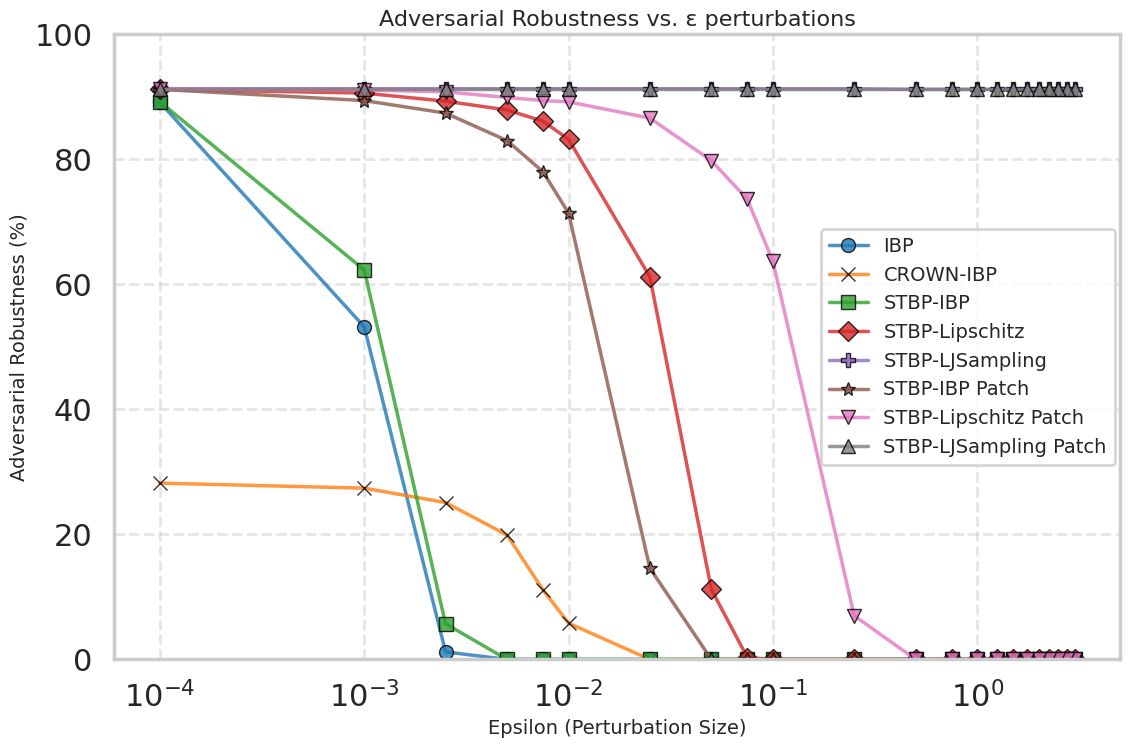

time: 428 ms (started: 2026-03-25 15:23:38 +00:00)


In [38]:
acc = {
    'ibp': ([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.2, 53.2, 89.1], 'IBP'),
    # 'sibp_lp': ([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.8, 40.2, 57.9, 73.3, 83.89999999999999, 88.5, 89.1, 89.9, 90.5, 90.9, 91.10000000000001], 'STBP'),
    # 'sibp_lp_patch': ([91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3], 'STBP-Patch'),
    'crown_ibp':([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.800000000000001, 11.1, 19.900000000000002, 25.1, 27.400000000000002, 28.199999999999996], 'CROWN-IBP'),
    'closed_ibp': ([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.7, 62.3, 89.2], 'STBP-IBP'),
    'closed_lips': ([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.3, 11.200000000000001, 61.199999999999996, 83.2, 86.1, 87.9, 89.3, 90.60000000000001, 91.2], 'STBP-Lipschitz'),
    'closed_lj': ([91.2, 91.2, 91.2, 91.2, 91.2, 91.2, 91.2, 91.2, 91.2, 91.2, 91.2, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3], 'STBP-LJSampling'),
    'closed_ibp_patch': ([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 14.6, 71.39999999999999, 78.0, 83.0, 87.4, 89.4, 91.2], 'STBP-IBP Patch'),
    'closed_lips_patch': ([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 7.000000000000001, 63.7, 73.6, 79.80000000000001, 86.6, 89.2, 89.4, 89.9, 90.8, 91.10000000000001, 91.2], 'STBP-Lipschitz Patch'),
    'closed_lj_patch': ([91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3, 91.3], 'STBP-LJSampling Patch'),
}

epsilons = [3, 2.75, 2.50, 2.25, 2, 1.75, 1.5, 1.25, 1, 0.75, 0.5, 0.25, 0.1, 0.075, 0.05, 0.025, 0.01, 0.0075, 0.005, 0.0025, 0.001, 0.0001]

epsilons_axis =(epsilons, "Epsilon (Perturbation Size)")
plot_accuracy_with_dict(acc, epsilons_axis) 